# 05b — Analisis Kasus Per Citra, Error Overlay, dan Histogram Validasi

## Tujuan dan batas analisis

**Pertanyaan:** pada citra validasi mana *baseline* Otsu dan Lab K-means saling mengungguli atau sama-sama lemah, seperti apa pola kesalahan spasial (`TP`, `FP`, `FN`) masing-masing metode pada citra yang sama, dan bagaimana distribusi intensitas maupun ruang warna fisik CIE Lab menjelaskan perilaku tersebut?

**Kohort dan pasangan metode:**
- Kohort tetap: **372 citra `val`** (`split_manifest.csv`). Tidak menyentuh `test` dan tidak melakukan *tuning* parameter baru.
- Pasangan utama (*default*): **`otsu_M0`** (Metode A) vs **`k4_M0`** (Metode B).
- Pasangan sekunder (*postprocessed*): **`otsu_M2`** vs **`k4_M1`**.
- Prediksi dihitung dari citra RGB penuh (`224×224 = 50.176` piksel) hanya memakai artefak `train` yang sudah dibekukan; *ground truth* (`mask >= 128`) dipakai sesudah prediksi murni untuk evaluasi, *error overlay*, dan diagnostik *post-hoc*.

In [1]:
%matplotlib inline

from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ebhi_dip import (
    EXPECTED_CATEGORIES,
    RANKING_MODES,
    SUPPORTED_METHODS,
    TIE_TOLERANCE,
    build_case,
    case_metrics_table,
    compute_shared_lab_edges,
    configure_notebook_style,
    find_project_root,
    finish_figure,
    format_case_metrics_for_display,
    has_raw_dataset,
    load_split_manifest,
    load_validation_results,
    method_label,
    pair_scores,
    paired_outcome_counts,
    plot_fg_vs_bg_intensity_histograms,
    plot_image_histograms,
    plot_morphology_stage_comparison,
    plot_paired_scatter,
    plot_region_lab_histograms,
    plot_score_histograms,
    plot_segmentation_case,
    rank_cases,
    rgb_to_lab,
    select_distinct_cases,
    sha256_bytes,
    verify_frozen_split,
)

# Parameter statis (fallback utama apabila dibuka tanpa widget renderer)
PROJECT_ROOT_OVERRIDE = None
DATA_ROOT_OVERRIDE = None
METHOD_A = "otsu_M0"
METHOD_B = "k4_M0"
SECONDARY_PAIR = ("otsu_M2", "k4_M1")
CATEGORY_FILTER = None          # None untuk seluruh 6 kategori, atau nama kategori spesifik
RANKING_MODE = "default_four"   # "default_four" (maks 4 citra unik) atau salah satu dari RANKING_MODES
TOP_N_TABLE = 5                 # Jumlah baris per mode pada tabel ringkasan ranking
GALLERY_N = 3                   # Dipakai bila RANKING_MODE berupa satu mode spesifik
SAMPLE_ID_OVERRIDE = None       # Isi sample_id validasi spesifik bila ingin memeriksa satu citra tertentu
HISTOGRAM_DENSITY = False       # False = "Jumlah piksel", True = "Kerapatan" (luas integral = 1)
HISTOGRAM_BINS = 64
EXPORT_FIGURES = False
SHOW_INTERACTIVE_WIDGETS = True

ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
SPLIT_SHA = verify_frozen_split(ROOT)
RAW_AVAILABLE = has_raw_dataset(ROOT, data_root_override=DATA_ROOT_OVERRIDE)
configure_notebook_style()

protected_files = {
    "split_manifest": ROOT / "data/metadata/split_manifest.csv",
    "otsu_morph_val": ROOT / "results/otsu_morph_val.csv",
    "kmeans_morph_val": ROOT / "results/kmeans_morph_val.csv",
    "kmeans_run": ROOT / "results/kmeans_morph_val_run.json",
    "otsu_config": ROOT / "configs/otsu_raw.json",
    "model_k4": ROOT / "models/kmeans_lab_k4_mapped.json",
}
input_hashes_before = {name: sha256_bytes(path) for name, path in protected_files.items()}

results = load_validation_results(ROOT)
split_df = load_split_manifest(ROOT, verify=False)

display(
    pd.DataFrame(
        {
            "parameter": ["Python", "Pasangan utama", "Filter kategori", "Mode histogram", "Raw dataset tersedia"],
            "nilai": [
                platform.python_version(),
                f"{METHOD_A} vs {METHOD_B}",
                CATEGORY_FILTER or "Semua 6 kategori (n=372)",
                "Kerapatan (integral=1)" if HISTOGRAM_DENSITY else "Jumlah piksel (counts)",
                str(RAW_AVAILABLE),
            ],
        }
    )
)

,parameter,nilai
0,Python,3.14.0
1,Pasangan utama,otsu_M0 vs k4_M0
2,Filter kategori,Semua 6 kategori (n=372)
3,Mode histogram,Jumlah piksel (counts)
4,Raw dataset tersedia,True


## 1. Perbandingan berpasangan per citra dan distribusi skor performa

Skor digabungkan secara *one-to-one* pada `sample_id` dengan definisi $\Delta\mathrm{Dice} = \mathrm{Dice}_A - \mathrm{Dice}_B$ dan toleransi *tie* `1e-12` (`rtol = 0`).

> **Catatan metrik:** tabel *counts* di bawah menghitung berapa banyak citra individual di mana Metode A lebih tinggi, Metode B lebih tinggi, atau setara (*tie*). Ukuran frekuensi per citra ini memberi bobot sama pada tiap citra dan **berbeda** dari metrik seleksi utama proyek (*equal-category mean* Dice).

In [2]:
paired = pair_scores(
    results,
    METHOD_A,
    METHOD_B,
    category=CATEGORY_FILTER,
    tie_tolerance=TIE_TOLERANCE,
)
overall_counts, cat_counts = paired_outcome_counts(
    paired,
    expected_categories=EXPECTED_CATEGORIES if CATEGORY_FILTER is None else None,
)

paired_secondary = pair_scores(
    results,
    SECONDARY_PAIR[0],
    SECONDARY_PAIR[1],
    category=CATEGORY_FILTER,
    tie_tolerance=TIE_TOLERANCE,
)
sec_counts, _ = paired_outcome_counts(paired_secondary)

pair_summary_df = pd.DataFrame(
    [
        {
            "pasangan": f"{METHOD_A} (A) vs {METHOD_B} (B)",
            "A_lebih_tinggi": overall_counts["a_higher"],
            "B_lebih_tinggi": overall_counts["b_higher"],
            "tie": overall_counts["tie"],
            "total_citra": overall_counts["total"],
            "mean_dice_a": round(float(paired["dice_a"].mean()), 4),
            "mean_dice_b": round(float(paired["dice_b"].mean()), 4),
            "median_delta_dice": round(float(paired["delta_dice"].median()), 4),
        },
        {
            "pasangan": f"{SECONDARY_PAIR[0]} (A) vs {SECONDARY_PAIR[1]} (B)",
            "A_lebih_tinggi": sec_counts["a_higher"],
            "B_lebih_tinggi": sec_counts["b_higher"],
            "tie": sec_counts["tie"],
            "total_citra": sec_counts["total"],
            "mean_dice_a": round(float(paired_secondary["dice_a"].mean()), 4),
            "mean_dice_b": round(float(paired_secondary["dice_b"].mean()), 4),
            "median_delta_dice": round(float(paired_secondary["delta_dice"].median()), 4),
        },
    ]
).set_index("pasangan")
display(pair_summary_df)

,A_lebih_tinggi,B_lebih_tinggi,tie,total_citra,mean_dice_a,mean_dice_b,median_delta_dice
pasangan,,,,,,,
otsu_M0 (A) vs k4_M0 (B),96,276,0,372,0.7011,0.7652,-0.0513
otsu_M2 (A) vs k4_M1 (B),122,250,0,372,0.7065,0.7651,-0.0428


In [3]:
display(
    cat_counts.rename(
        columns={
            "a_higher": f"{METHOD_A} lebih tinggi",
            "b_higher": f"{METHOD_B} lebih tinggi",
            "tie": "Tie (|Δ| <= 1e-12)",
            "total": "Total citra",
        }
    )
)

,otsu_M0 lebih tinggi,k4_M0 lebih tinggi,Tie (|Δ| <= 1e-12),Total citra
category,,,,
Adenocarcinoma,42,89,0,131
High-grade IN,8,12,0,20
Low-grade IN,19,88,0,107
Normal,4,6,0,10
Polyp,21,75,0,96
Serrated adenoma,2,6,0,8


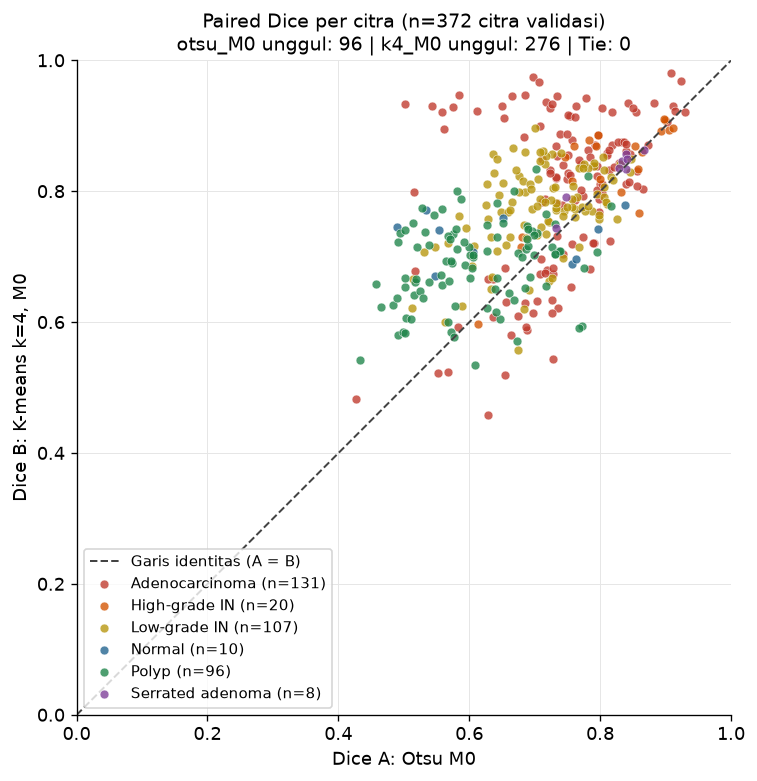

In [4]:
fig_sc = plot_paired_scatter(paired, tie_tolerance=TIE_TOLERANCE)
finish_figure(
    fig_sc,
    export_path=(ROOT / f"reports/figures/05b_paired_scatter_{METHOD_A}_vs_{METHOD_B}.png") if EXPORT_FIGURES else None,
)

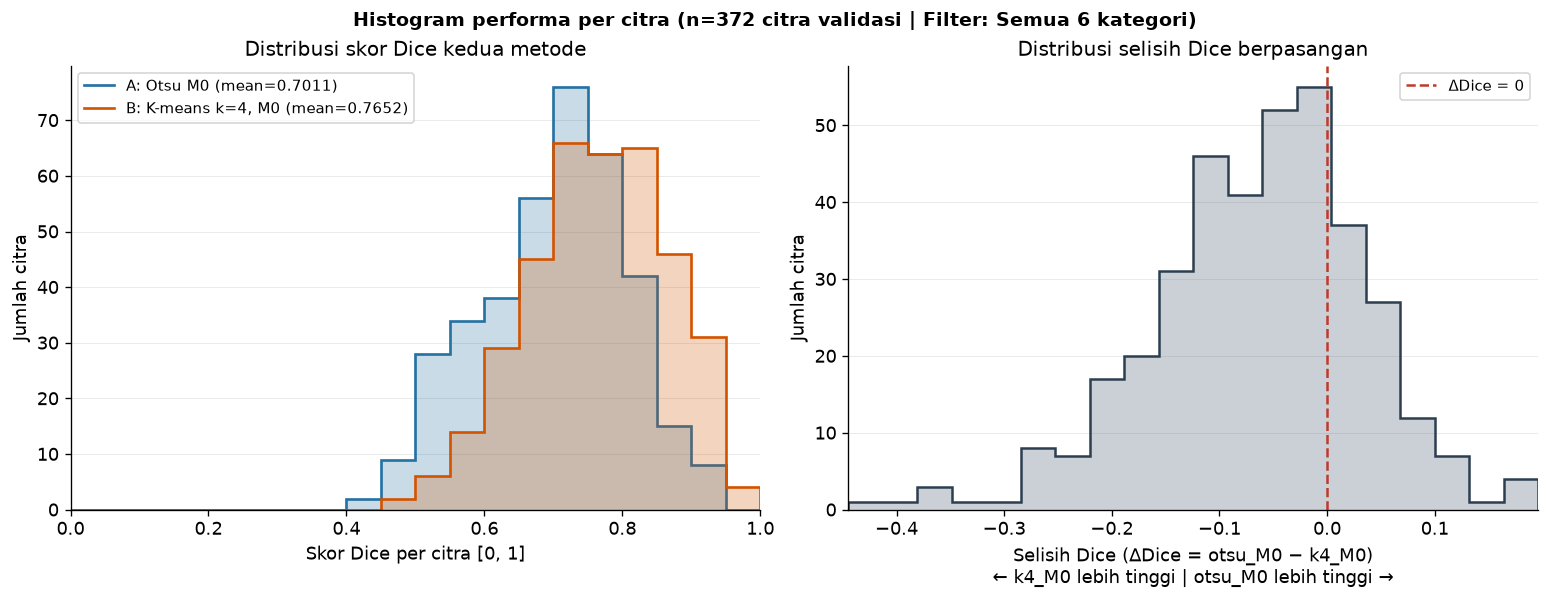

In [5]:
fig_sh = plot_score_histograms(
    paired,
    bins=20,
    category_label=CATEGORY_FILTER or "Semua 6 kategori",
)
finish_figure(
    fig_sh,
    export_path=(ROOT / f"reports/figures/05b_score_histograms_{METHOD_A}_vs_{METHOD_B}.png") if EXPORT_FIGURES else None,
)

**Observasi distribusi performa per citra.**
- Pada pasangan mentah `otsu_M0` vs `k4_M0`, `k4_M0` unggul pada **276 dari 372 citra** (`74,2%`), sedangkan `otsu_M0` tetap unggul pada **96 citra** (`25,8%`) dan **0 *tie***.
- Setelah pascapemrosesan morfologi (`otsu_M2` vs `k4_M1`), jumlah citra di mana Otsu unggul naik menjadi **122 citra** dibanding **250 citra** untuk K-means (`0` *tie*), menunjukkan bahwa tidak ada satu metode yang mendominasi secara mutlak di seluruh kondisi sediaan.

## 2. Tabel ranking kasus validasi

Perbedaan penting terminologi ranking:
- **`worst_a` / `worst_b`:** skor Dice absolut paling rendah pada metode tersebut (metode pembanding bisa saja juga rendah atau jauh lebih tinggi).
- **`a_advantage` / `b_advantage`:** selisih berpasangan terbesar ($\Delta\mathrm{Dice} > 10^{-12}$ terbesar atau $\Delta\mathrm{Dice} < -10^{-12}$ terkecil).
- **`both_poor`:** $\max(\mathrm{Dice}_A, \mathrm{Dice}_B)$ terendah sehingga kedua metode sama-sama lemah pada citra yang sama.

In [6]:
ranking_frames = []
empty_modes = []
for mode_name in RANKING_MODES:
    ranked_df = rank_cases(paired, mode=mode_name, n=TOP_N_TABLE, tie_tolerance=TIE_TOLERANCE)
    if ranked_df.empty:
        empty_modes.append(mode_name)
    else:
        ranking_frames.append(ranked_df)

if empty_modes:
    display(
        Markdown(
            f"**Kelompok ranking kosong pada toleransi `{TIE_TOLERANCE}`:** `{', '.join(empty_modes)}` "
            "(tidak ada pasangan skor yang memenuhi kriteria tersebut; tidak diisi dengan selisih arah berlawanan)."
        )
    )

combined_rankings = pd.concat(ranking_frames, ignore_index=True)
display_cols = [
    "selection_mode",
    "sample_id",
    "category",
    "group_id",
    "dice_a",
    "iou_a",
    "dice_b",
    "iou_b",
    "delta_dice",
    "selection_reason",
]
display(
    combined_rankings[display_cols].style.format(
        {
            "dice_a": "{:.4f}",
            "iou_a": "{:.4f}",
            "dice_b": "{:.4f}",
            "iou_b": "{:.4f}",
            "delta_dice": "{:+.4f}",
        }
    )
)

**Kelompok ranking kosong pada toleransi `1e-12`:** `ties` (tidak ada pasangan skor yang memenuhi kriteria tersebut; tidak diisi dengan selisih arah berlawanan).

,selection_mode,sample_id,category,group_id,dice_a,iou_a,dice_b,iou_b,delta_dice,selection_reason
0,worst_a,Adenocarcinoma/GT2100009-1-400-003,Adenocarcinoma,GT2100009,0.4271,0.2715,0.4828,0.3182,-0.0557,Worst otsu_M0 (Dice A terendah)
1,worst_a,Polyp/GT2014792-4-400-001,Polyp,GT2014792,0.4334,0.2766,0.5426,0.3724,-0.1093,Worst otsu_M0 (Dice A terendah)
2,worst_a,Polyp/GTxc2013935-1-400-002,Polyp,GTXC2013935,0.4573,0.2964,0.6583,0.4907,-0.2010,Worst otsu_M0 (Dice A terendah)
3,worst_a,Polyp/GT2014650-1-400-001,Polyp,GT2014650,0.4646,0.3026,0.6234,0.4528,-0.1588,Worst otsu_M0 (Dice A terendah)
4,worst_a,Polyp/GT2014792-3-400-003,Polyp,GT2014792,0.4831,0.3185,0.6262,0.4558,-0.1431,Worst otsu_M0 (Dice A terendah)
5,worst_b,Adenocarcinoma/GTxc2013489-1-400-006,Adenocarcinoma,GTXC2013489,0.6289,0.4587,0.4580,0.2970,+0.1709,Worst k4_M0 (Dice B terendah)
6,worst_b,Adenocarcinoma/GT2100009-1-400-003,Adenocarcinoma,GT2100009,0.4271,0.2715,0.4828,0.3182,-0.0557,Worst k4_M0 (Dice B terendah)
7,worst_b,Adenocarcinoma/GTXC2015344-2-400-008,Adenocarcinoma,GTXC2015344,0.6552,0.4872,0.5192,0.3507,+0.1359,Worst k4_M0 (Dice B terendah)
8,worst_b,Adenocarcinoma/GTxc2013451-1-400-004,Adenocarcinoma,GTXC2013451,0.5527,0.3819,0.5220,0.3532,+0.0307,Worst k4_M0 (Dice B terendah)
9,worst_b,Adenocarcinoma/GTXC2015401-1-400-003,Adenocarcinoma,GTXC2015401,0.5672,0.3959,0.5235,0.3546,+0.0437,Worst k4_M0 (Dice B terendah)


## 3. Pemilihan kasus untuk inspeksi visual terpadu

Secara *default* (`RANKING_MODE = "default_four"`), dipilih **maksimal empat citra berbeda**: `worst_a`, `worst_b`, `a_advantage` terbesar, dan `b_advantage` terbesar. Jika satu citra terpilih oleh lebih dari satu kriteria, kasus tersebut dideduplikasi dan seluruh alasan pemilihannya digabungkan.

In [7]:
if SAMPLE_ID_OVERRIDE is not None:
    matched = paired.loc[paired["sample_id"].eq(SAMPLE_ID_OVERRIDE)].copy()
    if matched.empty:
        raise KeyError(f"SAMPLE_ID_OVERRIDE '{SAMPLE_ID_OVERRIDE}' tidak ditemukan pada kohort validasi aktif.")
    matched["selection_modes"] = [("manual_sample_id",)] * len(matched)
    matched["selection_reasons"] = [f"Pilihan manual sample_id={SAMPLE_ID_OVERRIDE}"] * len(matched)
    selected_cases_df = matched.reset_index(drop=True)
elif RANKING_MODE == "default_four":
    selected_cases_df = select_distinct_cases(
        paired,
        mode_specs=(("worst_a", 1), ("worst_b", 1), ("a_advantage", 1), ("b_advantage", 1)),
        tie_tolerance=TIE_TOLERANCE,
    )
else:
    single_mode_df = rank_cases(paired, mode=RANKING_MODE, n=GALLERY_N, tie_tolerance=TIE_TOLERANCE)
    selected_cases_df = single_mode_df.rename(columns={"selection_reason": "selection_reasons"}).assign(
        selection_modes=lambda d: [(m,) for m in d["selection_mode"]]
    )

assert len(selected_cases_df) <= 4 or RANKING_MODE != "default_four"
display(
    selected_cases_df[
        ["sample_id", "category", "group_id", "dice_a", "dice_b", "delta_dice", "selection_reasons"]
    ].style.format({"dice_a": "{:.4f}", "dice_b": "{:.4f}", "delta_dice": "{:+.4f}"})
)

,sample_id,category,group_id,dice_a,dice_b,delta_dice,selection_reasons
0,Adenocarcinoma/GT2100009-1-400-003,Adenocarcinoma,GT2100009,0.4271,0.4828,-0.0557,Worst otsu_M0 (Dice A terendah)
1,Adenocarcinoma/GTxc2013489-1-400-006,Adenocarcinoma,GTXC2013489,0.6289,0.4580,+0.1709,Worst k4_M0 (Dice B terendah)
2,Adenocarcinoma/GTXC2110135-2-400-008,Adenocarcinoma,GTXC2110135,0.7275,0.5440,+0.1836,Keunggulan terbesar otsu_M0 (ΔDice > 0 terbesar)
3,Adenocarcinoma/GTXC2013386-1-400-011,Adenocarcinoma,GTXC2013386,0.5015,0.9341,-0.4326,Keunggulan terbesar k4_M0 (ΔDice < 0 terkecil)


## 4. Galeri perbandingan berpasangan (2×3), *error overlay*, dan histogram piksel (6-panel)

Untuk setiap citra terpilih:
1. **Tabel metrik per kasus** menampilkan `Dice`, `IoU`, *pixel precision*, *pixel recall*, cakupan *foreground* prediksi vs referensi, serta jumlah piksel `TP`, `FP`, `FN`, dan `TN` (nilai *precision*/*recall* berpenyebut nol ditandai eksplisit sebagai `undefined (NaN)`).
2. **Galeri 2×3** menampilkan kedua metode pada citra yang sama beserta *error overlay* (`TP` hijau, `FP` oranye, `FN` magenta, `TN` transparan).
3. **Histogram citra 6-panel** menampilkan RGB (`0–255`), `grayscale` dengan garis *threshold* Otsu per citra (`polarity = dark`), *encoding* *raw reference mask* dengan garis tetap `128` (**bukan** *threshold* Otsu citra), serta kanal fisik CIE Lab `L*`, `a*` (*signed*), dan `b*` (*signed*) menggunakan batas *bin* Lab bersama lintas kasus terpilih.

In [8]:
if not RAW_AVAILABLE:
    display(
        Markdown(
            "> **Citra mentah tidak tersedia (`data/raw/EBHI-SEG/` tidak ditemukan).** "
            "Tabel ranking, *paired scatter*, dan histogram skor berbasis CSV telah dijalankan penuh di atas, "
            "tetapi verifikasi paritas inferensi citra asli, galeri *error overlay*, dan histogram intensitas/Lab "
            "belum dijalankan pada *checkout* ini."
        )
    )
    built_cases = []
else:
    built_cases = [
        build_case(
            ROOT,
            row=case_row,
            method_a=METHOD_A,
            method_b=METHOD_B,
            selection_reasons=case_row["selection_reasons"],
            data_root_override=DATA_ROOT_OVERRIDE,
            split_df=split_df,
        )
        for _, case_row in selected_cases_df.iterrows()
    ]
    if built_cases:
        shared_lab_edges = compute_shared_lab_edges(
            [rgb_to_lab(c.image_rgb) for c in built_cases],
            bins=HISTOGRAM_BINS,
        )

In [9]:
if 0 < len(built_cases):
    case_obj = built_cases[0]
    display(
        Markdown(
            f"### Kasus 1/{len(built_cases)}: `{case_obj.sample_id}` "
            f"(`{case_obj.category}`, Group `{case_obj.group_id}`)\n"
            f"- **Alasan pemilihan:** {'; '.join(case_obj.selection_reasons)}\n"
            f"- **Paritas CSV (`atol=1e-10`):** terverifikasi cocok "
            f"(`{case_obj.method_a}` Dice `{case_obj.metrics_a['dice']:.4f}`, "
            f"`{case_obj.method_b}` Dice `{case_obj.metrics_b['dice']:.4f}`, "
            f"`ΔDice = {case_obj.delta_dice:+.4f}`)."
        )
    )
    display(format_case_metrics_for_display(case_metrics_table(case_obj)))

### Kasus 1/4: `Adenocarcinoma/GT2100009-1-400-003` (`Adenocarcinoma`, Group `GT2100009`)
- **Alasan pemilihan:** Worst otsu_M0 (Dice A terendah)
- **Paritas CSV (`atol=1e-10`):** terverifikasi cocok (`otsu_M0` Dice `0.4271`, `k4_M0` Dice `0.4828`, `ΔDice = -0.0557`).

,Metode,Dice,IoU,Precision,Recall,Pred FG (%),Ref FG (%),TP,FP,FN,TN
method,,,,,,,,,,,
otsu_M0,Otsu M0,0.4271,0.2715,0.3964,0.4629,35.24%,30.18%,7009,10671,8134,24362
k4_M0,"K-means k=4, M0",0.4828,0.3182,0.3200,0.9822,92.63%,30.18%,14874,31602,269,3431


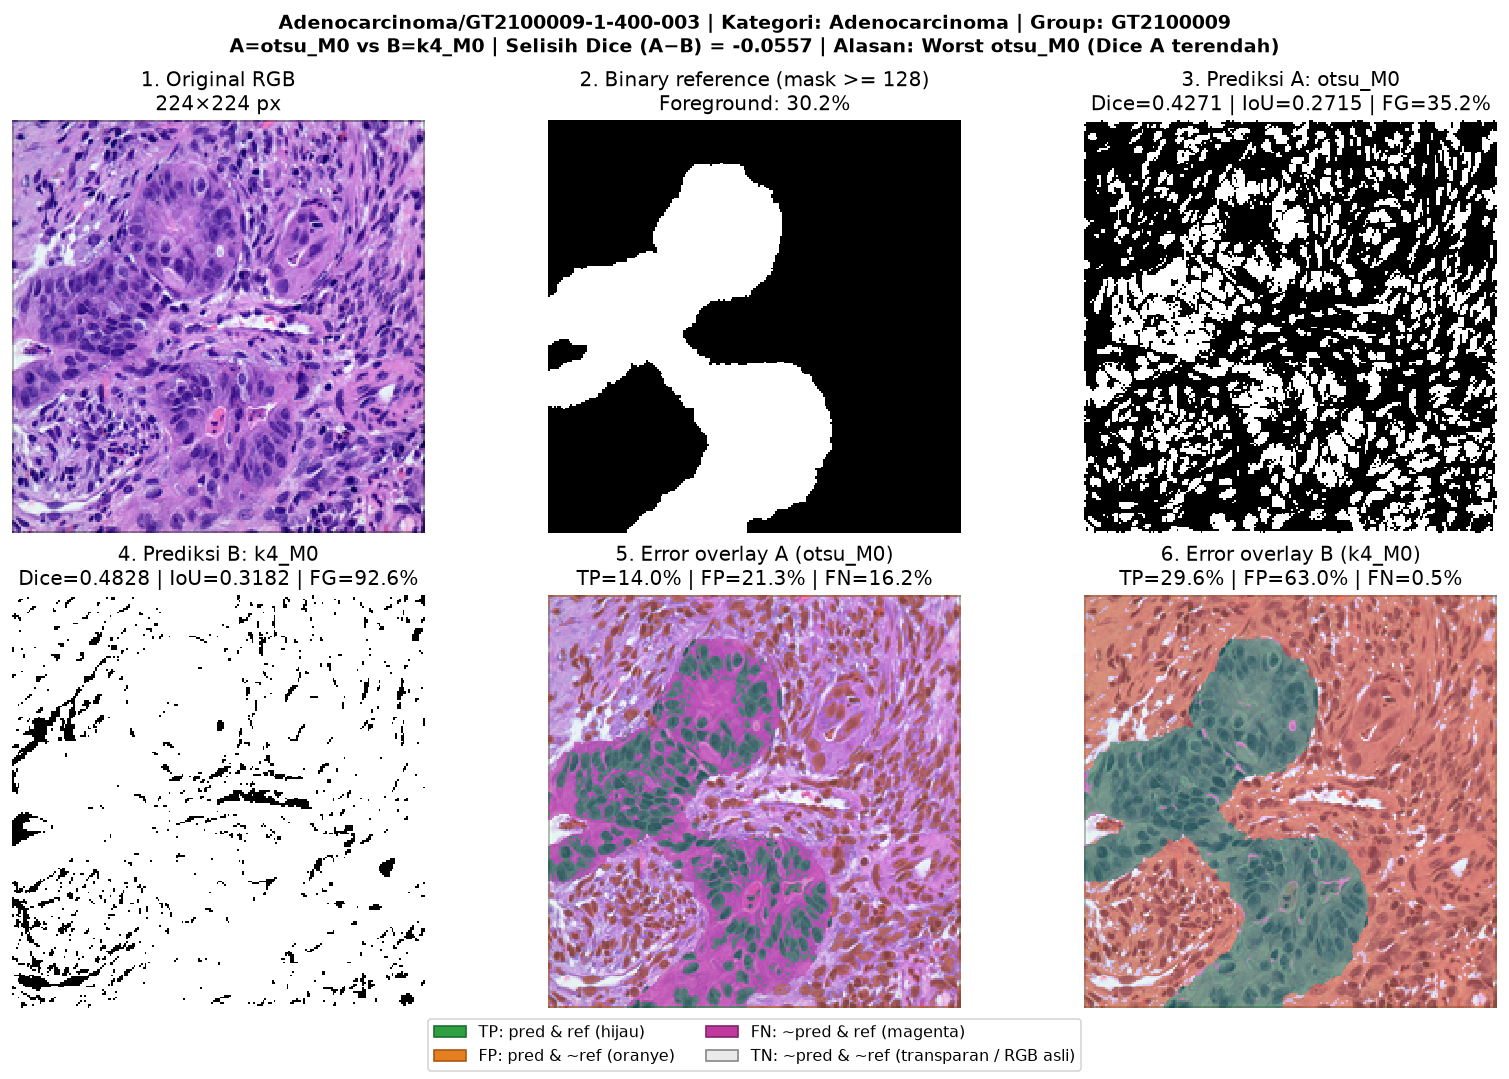

In [10]:
if 0 < len(built_cases):
    case_obj = built_cases[0]
    safe_slug = case_obj.sample_id.replace("/", "__").replace(" ", "_")
    fig_gallery = plot_segmentation_case(case_obj)
    finish_figure(
        fig_gallery,
        export_path=(ROOT / f"reports/figures/05b_case_1_{safe_slug}_gallery.png") if EXPORT_FIGURES else None,
    )

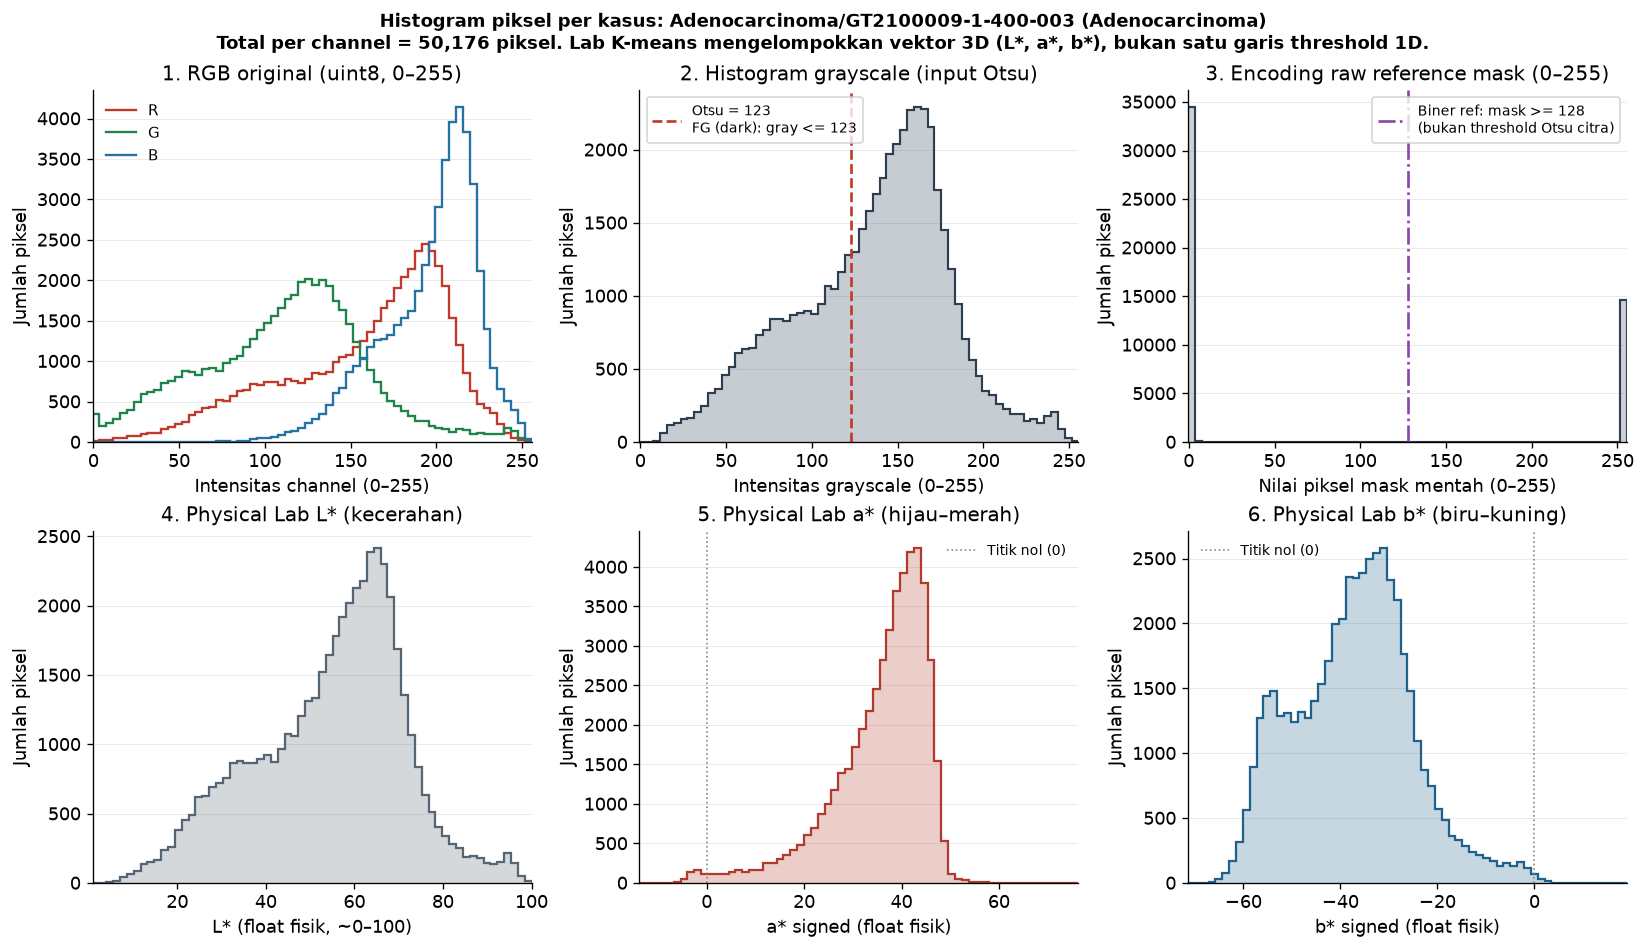

In [11]:
if 0 < len(built_cases):
    case_obj = built_cases[0]
    safe_slug = case_obj.sample_id.replace("/", "__").replace(" ", "_")
    fig_img_hist = plot_image_histograms(
        case_obj,
        bins=HISTOGRAM_BINS,
        lab_edges=shared_lab_edges,
        density=HISTOGRAM_DENSITY,
    )
    finish_figure(
        fig_img_hist,
        export_path=(ROOT / f"reports/figures/05b_case_1_{safe_slug}_histograms.png") if EXPORT_FIGURES else None,
    )

In [12]:
if 1 < len(built_cases):
    case_obj = built_cases[1]
    display(
        Markdown(
            f"### Kasus 2/{len(built_cases)}: `{case_obj.sample_id}` "
            f"(`{case_obj.category}`, Group `{case_obj.group_id}`)\n"
            f"- **Alasan pemilihan:** {'; '.join(case_obj.selection_reasons)}\n"
            f"- **Paritas CSV (`atol=1e-10`):** terverifikasi cocok "
            f"(`{case_obj.method_a}` Dice `{case_obj.metrics_a['dice']:.4f}`, "
            f"`{case_obj.method_b}` Dice `{case_obj.metrics_b['dice']:.4f}`, "
            f"`ΔDice = {case_obj.delta_dice:+.4f}`)."
        )
    )
    display(format_case_metrics_for_display(case_metrics_table(case_obj)))

### Kasus 2/4: `Adenocarcinoma/GTxc2013489-1-400-006` (`Adenocarcinoma`, Group `GTXC2013489`)
- **Alasan pemilihan:** Worst k4_M0 (Dice B terendah)
- **Paritas CSV (`atol=1e-10`):** terverifikasi cocok (`otsu_M0` Dice `0.6289`, `k4_M0` Dice `0.4580`, `ΔDice = +0.1709`).

,Metode,Dice,IoU,Precision,Recall,Pred FG (%),Ref FG (%),TP,FP,FN,TN
method,,,,,,,,,,,
otsu_M0,Otsu M0,0.6289,0.4587,0.5048,0.8339,43.13%,26.10%,10923,10717,2175,26361
k4_M0,"K-means k=4, M0",0.4580,0.2970,0.3002,0.9652,83.92%,26.10%,12642,29466,456,7612


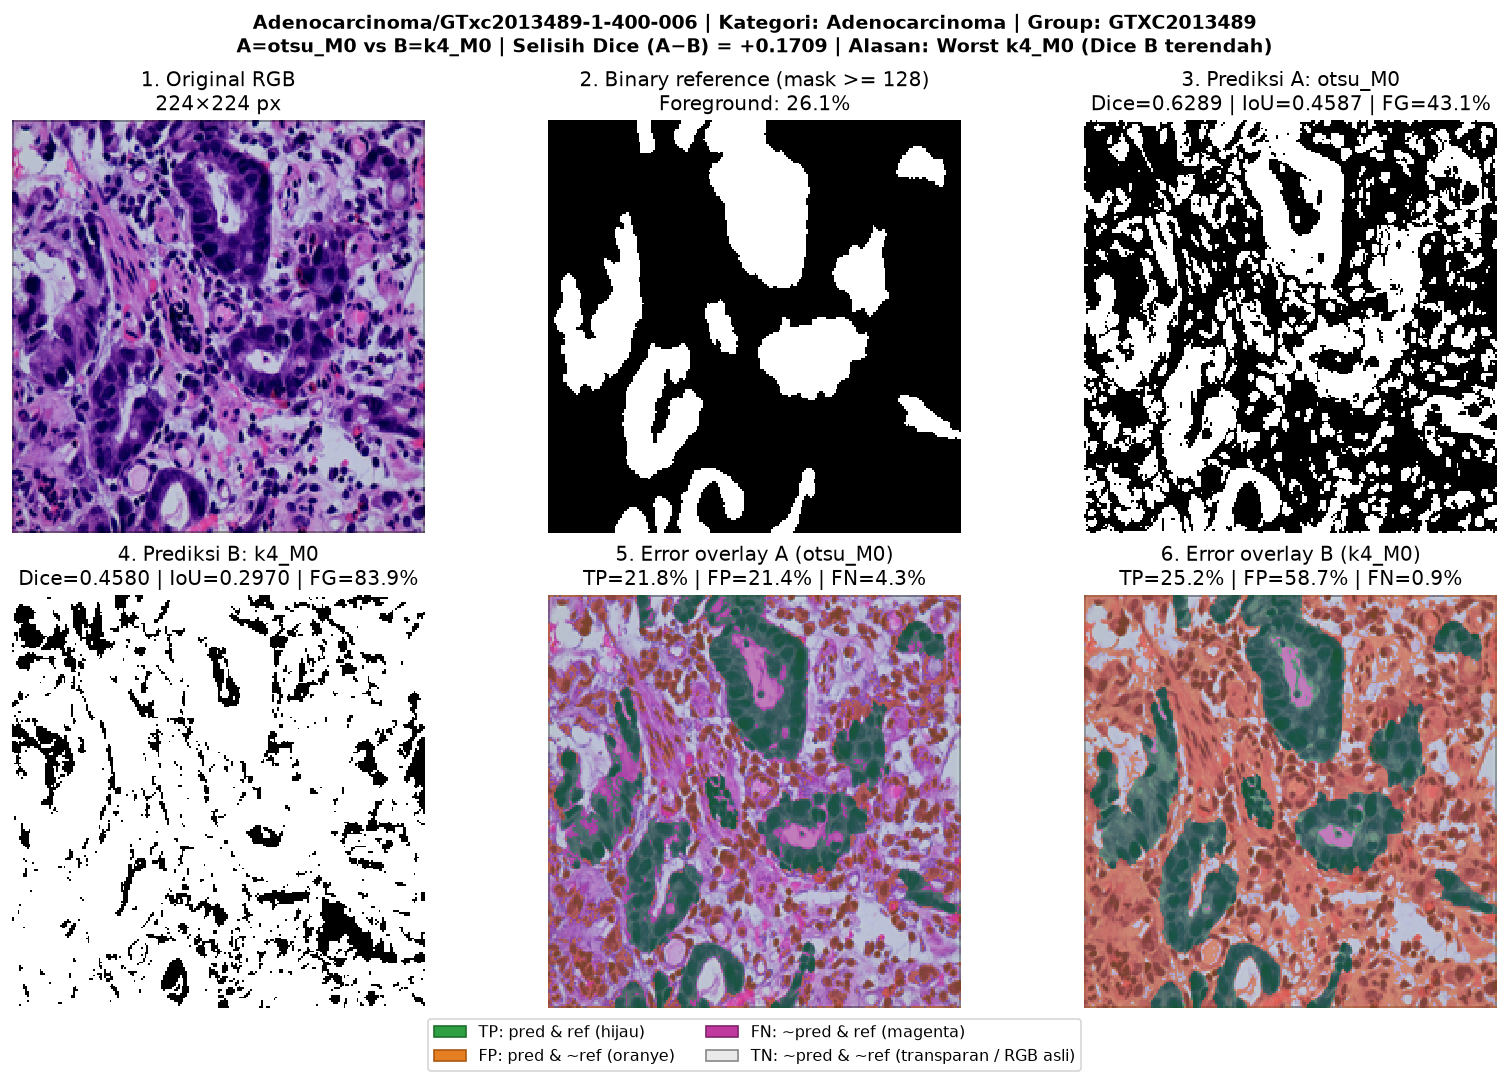

In [13]:
if 1 < len(built_cases):
    case_obj = built_cases[1]
    safe_slug = case_obj.sample_id.replace("/", "__").replace(" ", "_")
    fig_gallery = plot_segmentation_case(case_obj)
    finish_figure(
        fig_gallery,
        export_path=(ROOT / f"reports/figures/05b_case_2_{safe_slug}_gallery.png") if EXPORT_FIGURES else None,
    )

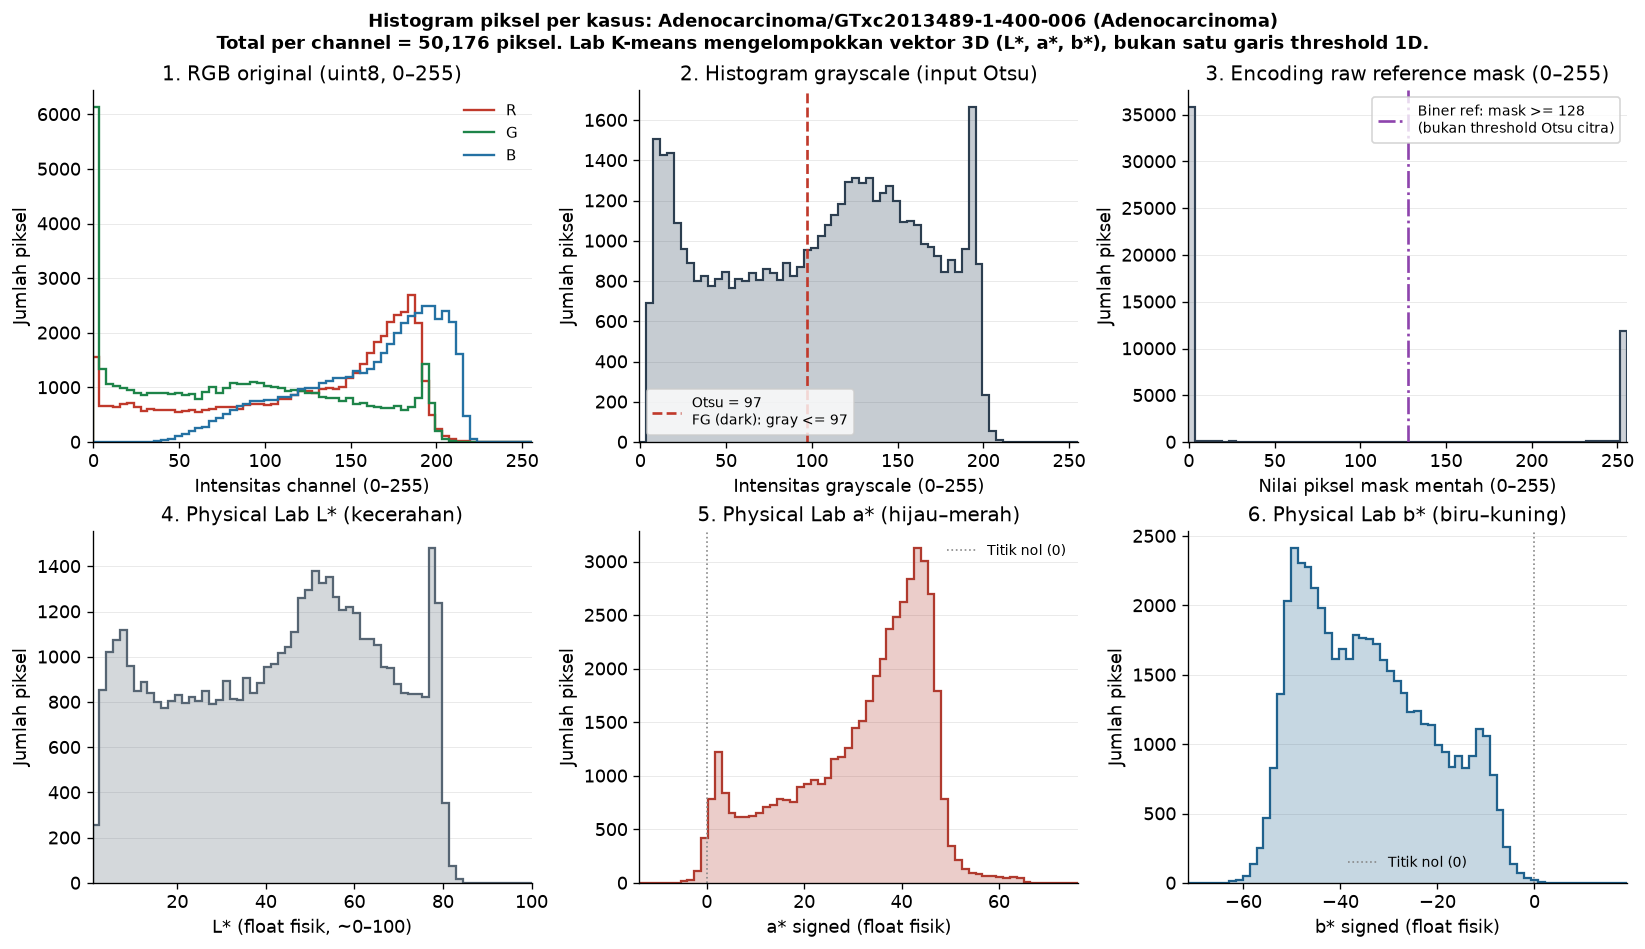

In [14]:
if 1 < len(built_cases):
    case_obj = built_cases[1]
    safe_slug = case_obj.sample_id.replace("/", "__").replace(" ", "_")
    fig_img_hist = plot_image_histograms(
        case_obj,
        bins=HISTOGRAM_BINS,
        lab_edges=shared_lab_edges,
        density=HISTOGRAM_DENSITY,
    )
    finish_figure(
        fig_img_hist,
        export_path=(ROOT / f"reports/figures/05b_case_2_{safe_slug}_histograms.png") if EXPORT_FIGURES else None,
    )

In [15]:
if 2 < len(built_cases):
    case_obj = built_cases[2]
    display(
        Markdown(
            f"### Kasus 3/{len(built_cases)}: `{case_obj.sample_id}` "
            f"(`{case_obj.category}`, Group `{case_obj.group_id}`)\n"
            f"- **Alasan pemilihan:** {'; '.join(case_obj.selection_reasons)}\n"
            f"- **Paritas CSV (`atol=1e-10`):** terverifikasi cocok "
            f"(`{case_obj.method_a}` Dice `{case_obj.metrics_a['dice']:.4f}`, "
            f"`{case_obj.method_b}` Dice `{case_obj.metrics_b['dice']:.4f}`, "
            f"`ΔDice = {case_obj.delta_dice:+.4f}`)."
        )
    )
    display(format_case_metrics_for_display(case_metrics_table(case_obj)))

### Kasus 3/4: `Adenocarcinoma/GTXC2110135-2-400-008` (`Adenocarcinoma`, Group `GTXC2110135`)
- **Alasan pemilihan:** Keunggulan terbesar otsu_M0 (ΔDice > 0 terbesar)
- **Paritas CSV (`atol=1e-10`):** terverifikasi cocok (`otsu_M0` Dice `0.7275`, `k4_M0` Dice `0.5440`, `ΔDice = +0.1836`).

,Metode,Dice,IoU,Precision,Recall,Pred FG (%),Ref FG (%),TP,FP,FN,TN
method,,,,,,,,,,,
otsu_M0,Otsu M0,0.7275,0.5718,0.6472,0.8307,47.61%,37.09%,15460,8429,3150,23137
k4_M0,"K-means k=4, M0",0.5440,0.3736,0.3764,0.9809,96.66%,37.09%,18254,30248,356,1318


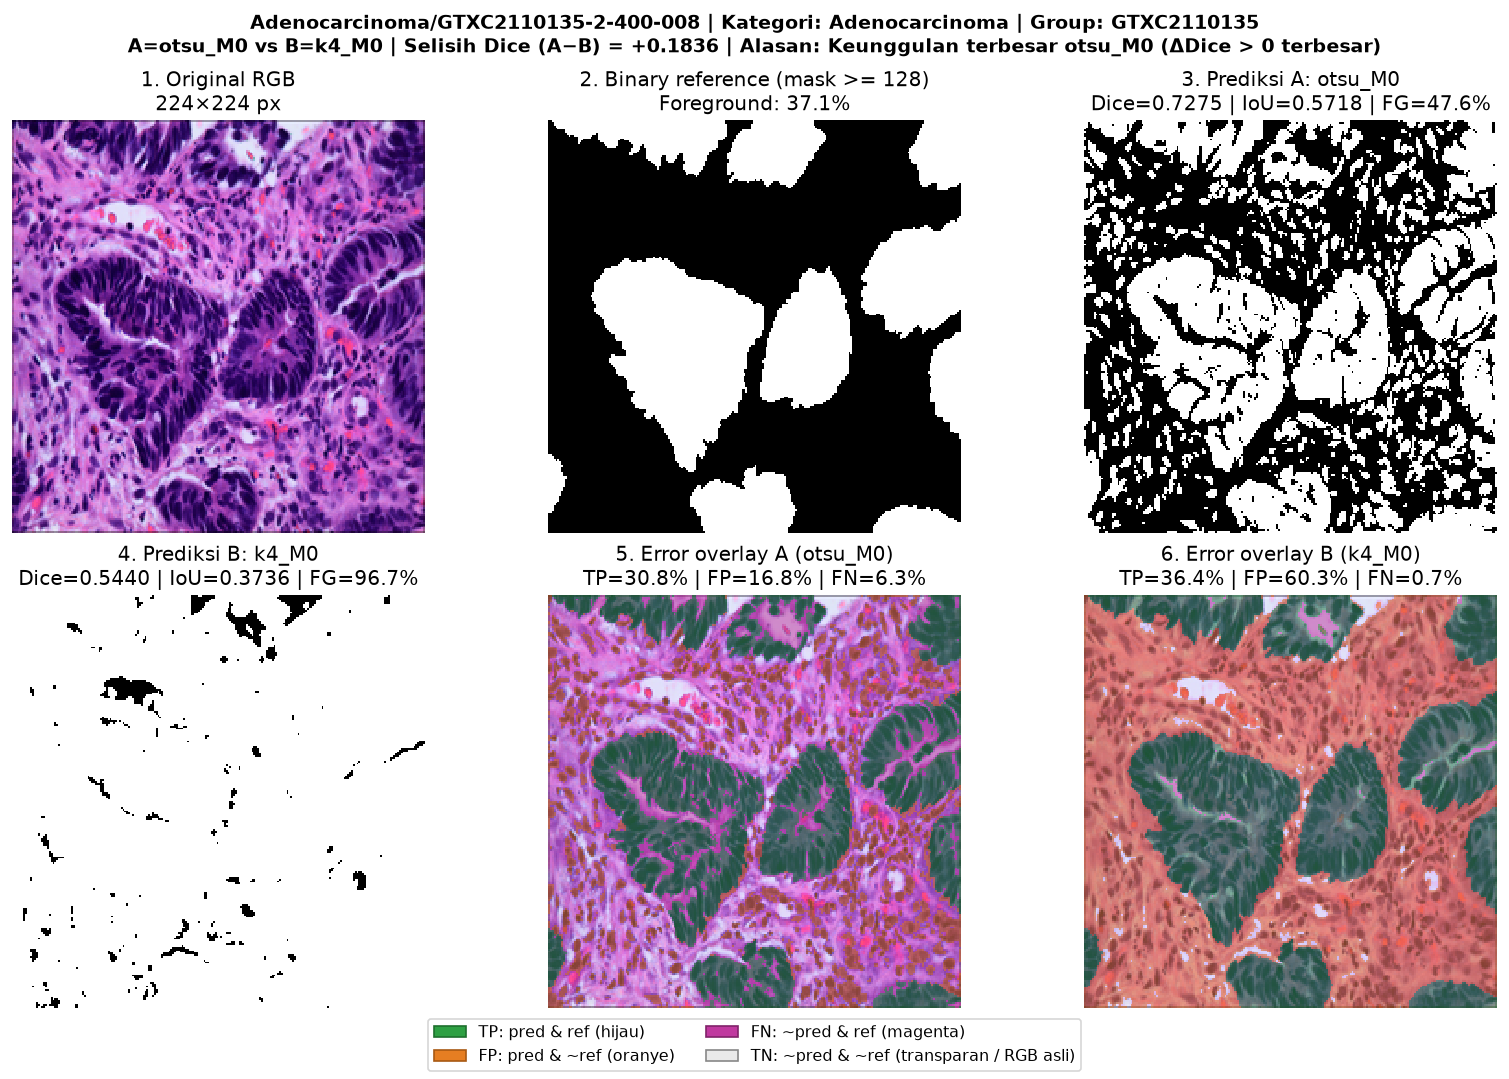

In [16]:
if 2 < len(built_cases):
    case_obj = built_cases[2]
    safe_slug = case_obj.sample_id.replace("/", "__").replace(" ", "_")
    fig_gallery = plot_segmentation_case(case_obj)
    finish_figure(
        fig_gallery,
        export_path=(ROOT / f"reports/figures/05b_case_3_{safe_slug}_gallery.png") if EXPORT_FIGURES else None,
    )

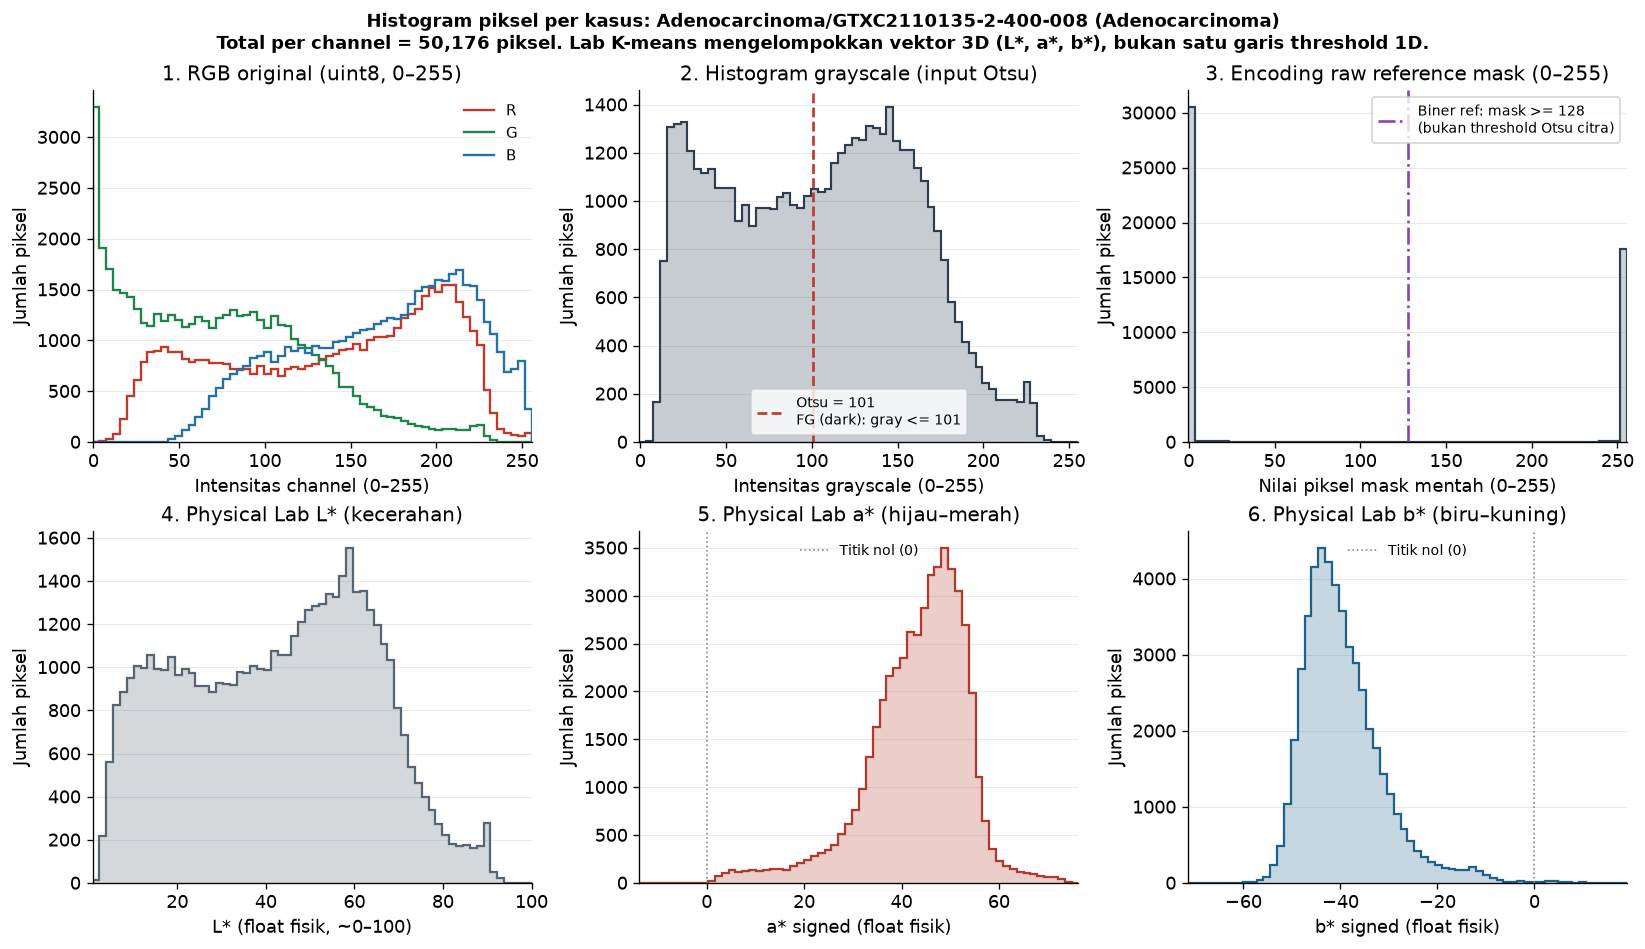

In [17]:
if 2 < len(built_cases):
    case_obj = built_cases[2]
    safe_slug = case_obj.sample_id.replace("/", "__").replace(" ", "_")
    fig_img_hist = plot_image_histograms(
        case_obj,
        bins=HISTOGRAM_BINS,
        lab_edges=shared_lab_edges,
        density=HISTOGRAM_DENSITY,
    )
    finish_figure(
        fig_img_hist,
        export_path=(ROOT / f"reports/figures/05b_case_3_{safe_slug}_histograms.png") if EXPORT_FIGURES else None,
    )

In [18]:
if 3 < len(built_cases):
    case_obj = built_cases[3]
    display(
        Markdown(
            f"### Kasus 4/{len(built_cases)}: `{case_obj.sample_id}` "
            f"(`{case_obj.category}`, Group `{case_obj.group_id}`)\n"
            f"- **Alasan pemilihan:** {'; '.join(case_obj.selection_reasons)}\n"
            f"- **Paritas CSV (`atol=1e-10`):** terverifikasi cocok "
            f"(`{case_obj.method_a}` Dice `{case_obj.metrics_a['dice']:.4f}`, "
            f"`{case_obj.method_b}` Dice `{case_obj.metrics_b['dice']:.4f}`, "
            f"`ΔDice = {case_obj.delta_dice:+.4f}`)."
        )
    )
    display(format_case_metrics_for_display(case_metrics_table(case_obj)))

### Kasus 4/4: `Adenocarcinoma/GTXC2013386-1-400-011` (`Adenocarcinoma`, Group `GTXC2013386`)
- **Alasan pemilihan:** Keunggulan terbesar k4_M0 (ΔDice < 0 terkecil)
- **Paritas CSV (`atol=1e-10`):** terverifikasi cocok (`otsu_M0` Dice `0.5015`, `k4_M0` Dice `0.9341`, `ΔDice = -0.4326`).

,Metode,Dice,IoU,Precision,Recall,Pred FG (%),Ref FG (%),TP,FP,FN,TN
method,,,,,,,,,,,
otsu_M0,Otsu M0,0.5015,0.3347,0.9971,0.3350,32.75%,97.48%,16385,48,32526,1217
k4_M0,"K-means k=4, M0",0.9341,0.8763,0.9975,0.8782,85.82%,97.48%,42954,108,5957,1157


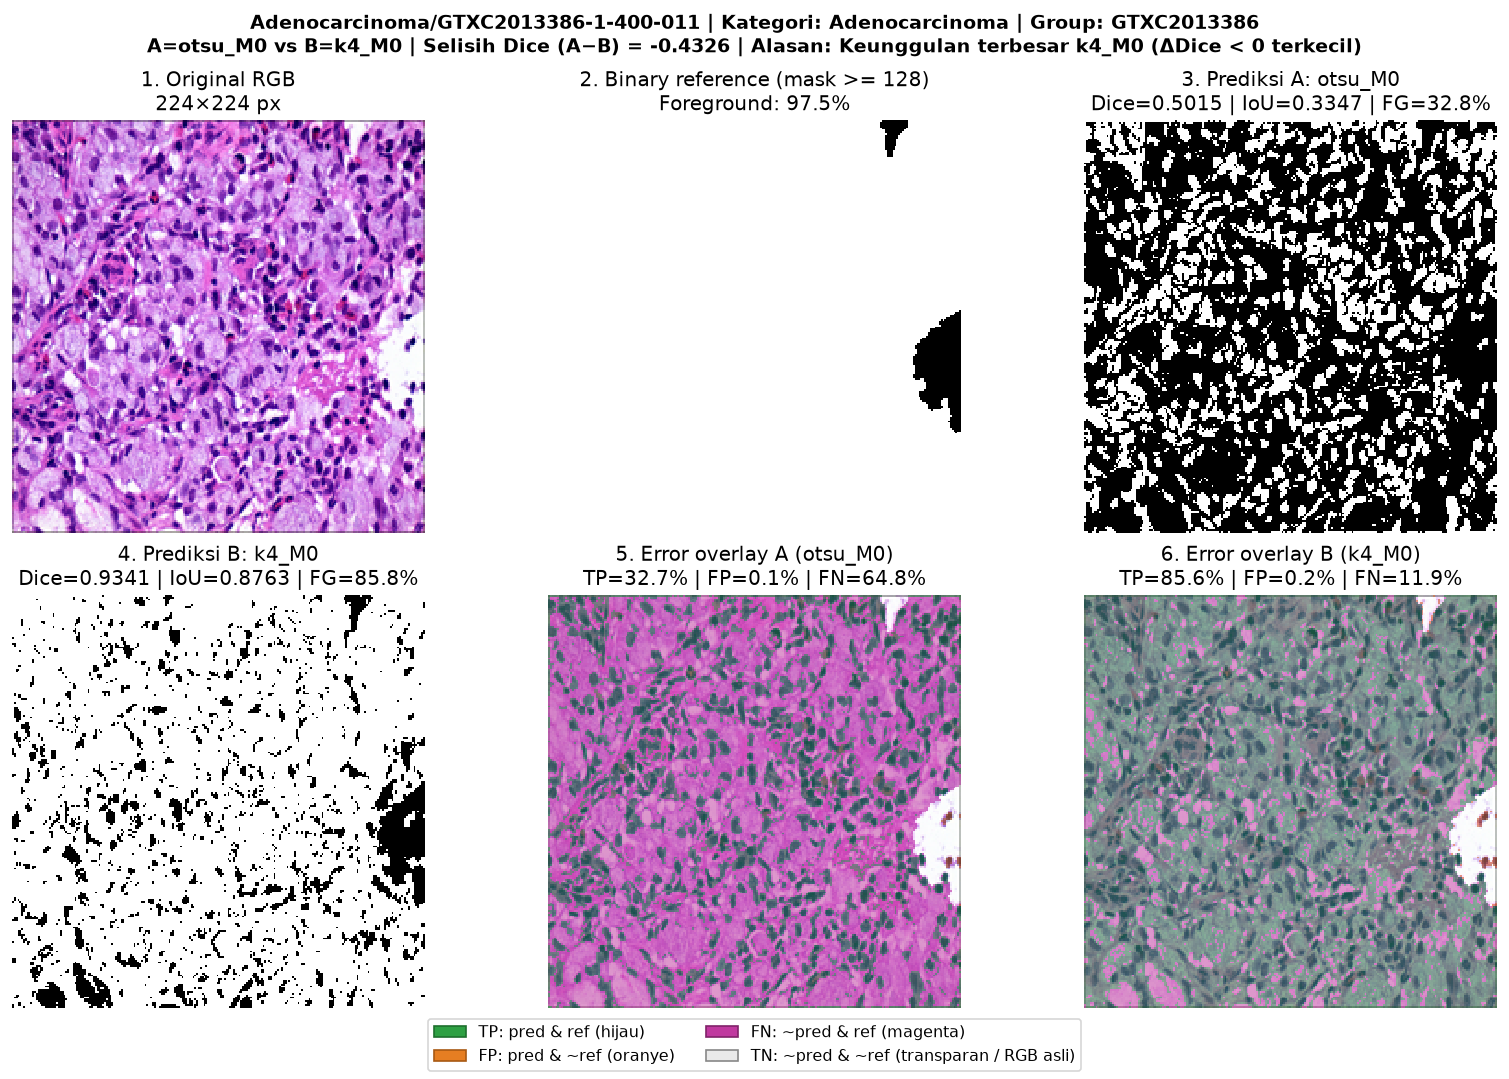

In [19]:
if 3 < len(built_cases):
    case_obj = built_cases[3]
    safe_slug = case_obj.sample_id.replace("/", "__").replace(" ", "_")
    fig_gallery = plot_segmentation_case(case_obj)
    finish_figure(
        fig_gallery,
        export_path=(ROOT / f"reports/figures/05b_case_4_{safe_slug}_gallery.png") if EXPORT_FIGURES else None,
    )

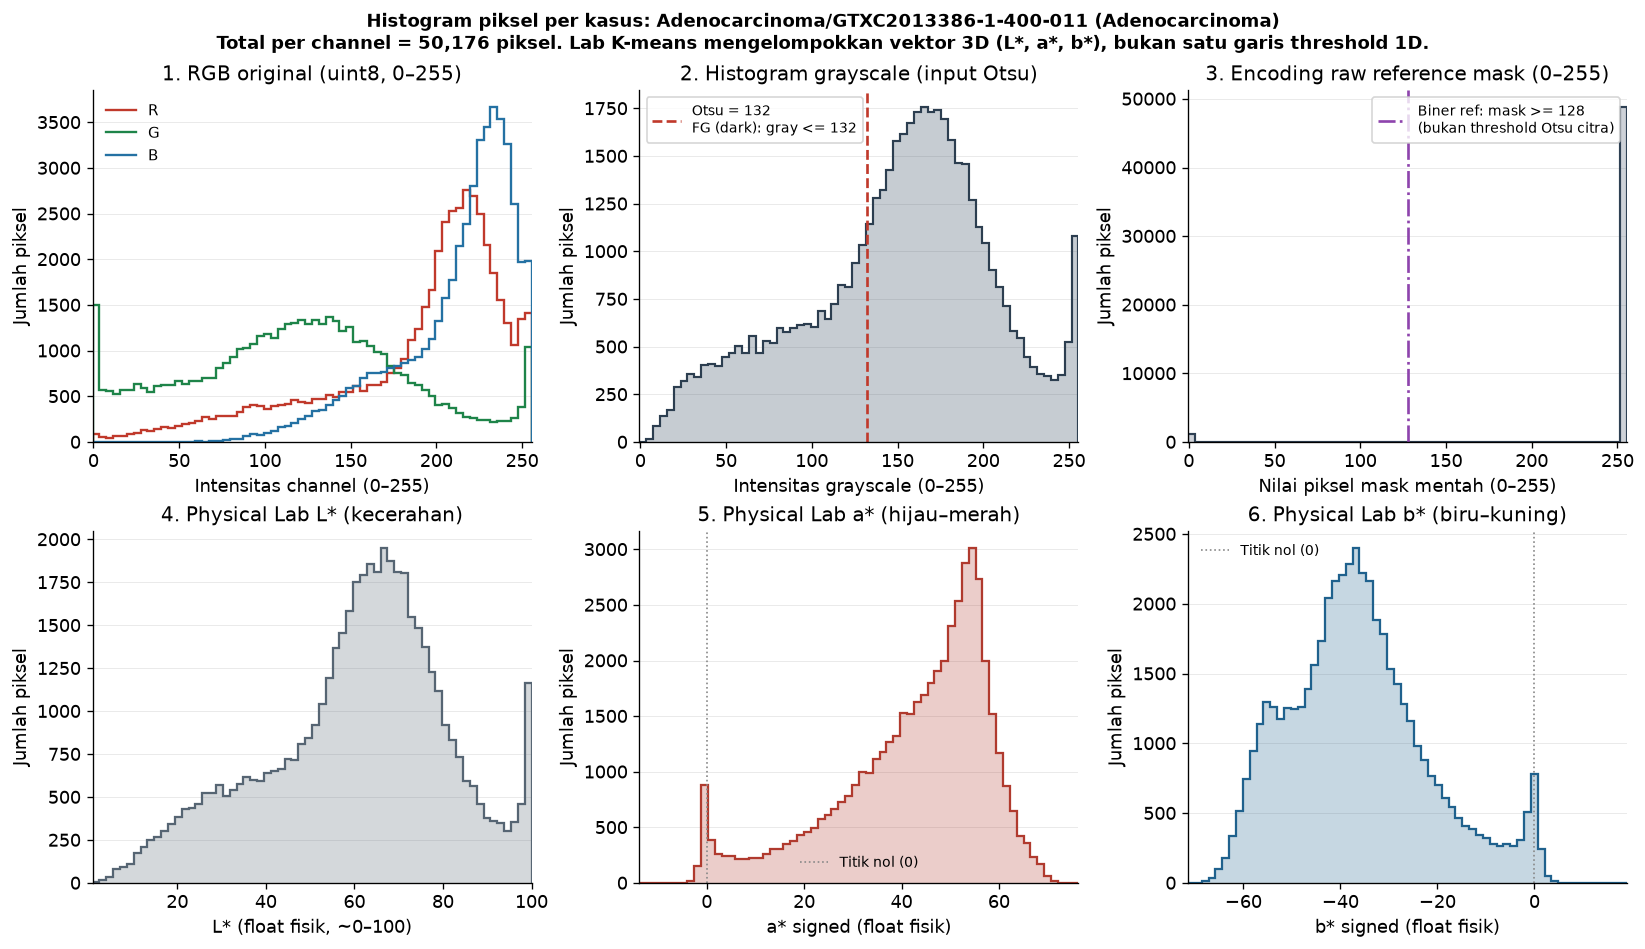

In [20]:
if 3 < len(built_cases):
    case_obj = built_cases[3]
    safe_slug = case_obj.sample_id.replace("/", "__").replace(" ", "_")
    fig_img_hist = plot_image_histograms(
        case_obj,
        bins=HISTOGRAM_BINS,
        lab_edges=shared_lab_edges,
        density=HISTOGRAM_DENSITY,
    )
    finish_figure(
        fig_img_hist,
        export_path=(ROOT / f"reports/figures/05b_case_4_{safe_slug}_histograms.png") if EXPORT_FIGURES else None,
    )

### Diagnostik *post-hoc*: distribusi Lab pada *foreground* per metode (Kasus 1)
Perbandingan di bawah menggunakan *bin edges* Lab yang sama untuk memeriksa rentang warna yang diambil oleh *reference*, prediksi A, dan prediksi B sesudah inferensi selesai.

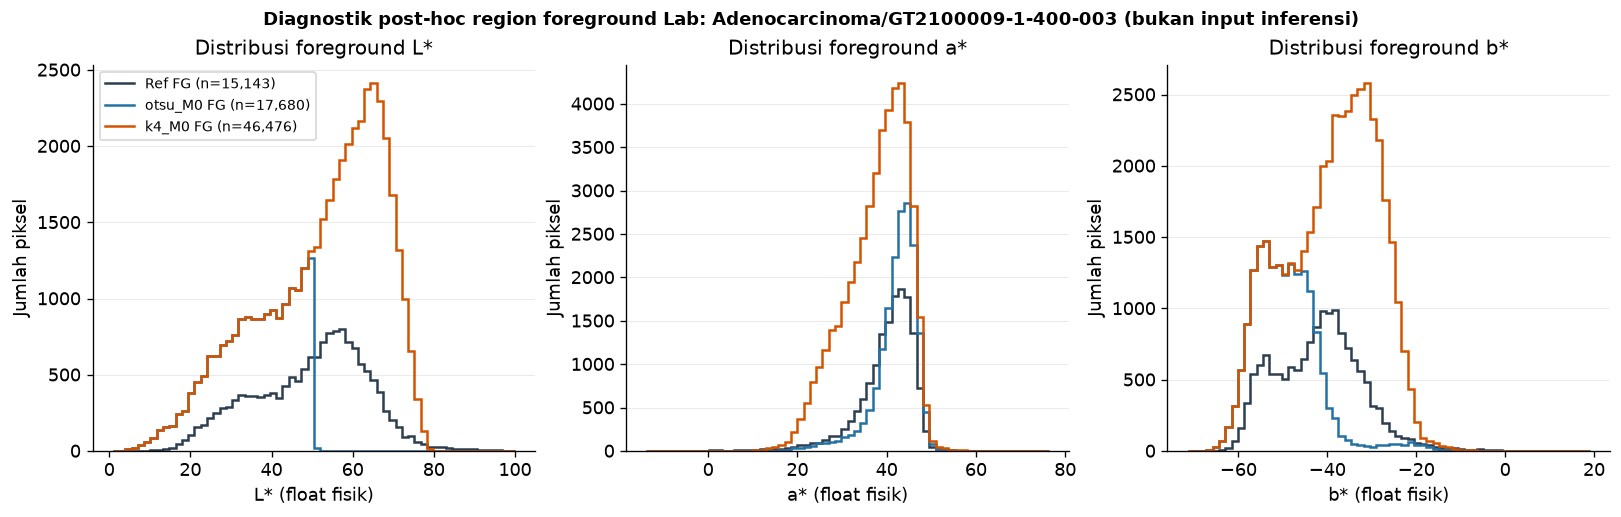

In [21]:
if built_cases:
    display(
        Markdown(
            "### Diagnostik *post-hoc*: distribusi Lab pada *foreground* per metode (Kasus 1)\n"
            "Perbandingan di bawah menggunakan *bin edges* Lab yang sama untuk memeriksa rentang warna "
            "yang diambil oleh *reference*, prediksi A, dan prediksi B sesudah inferensi selesai."
        )
    )
    fig_reg = plot_region_lab_histograms(
        built_cases[0],
        bins=48,
        lab_edges=shared_lab_edges,
        density=HISTOGRAM_DENSITY,
    )
    finish_figure(
        fig_reg,
        export_path=(ROOT / "reports/figures/05b_case_1_region_lab_diagnostic.png") if EXPORT_FIGURES else None,
    )

## 5. Interpretasi pola kegagalan dan keunggulan masing-masing metode

### Observasi langsung dari skor dan visualisasi
- **Keunggulan terbesar `k4_M0` (`Adenocarcinoma/GTXC2013386-1-400-011`, `ΔDice = -0.4326`):** *reference foreground* mencakup hampir seluruh bidang (`97,48%`). `otsu_M0` hanya mengambil piksel paling gelap (`gray <= 132`, cakupan `32,75%`) sehingga menimbulkan `FN` (*magenta*) sangat luas pada area jaringan yang lebih terang, sedangkan tiga *cluster* berwarna `k4_M0` menangkap `85,82%` bidang citra (`Dice = 0.9341`).
- **Keunggulan terbesar `otsu_M0` (`Adenocarcinoma/GTXC2110135-2-400-008`, `ΔDice = +0.1836`) dan `worst_b` (`Adenocarcinoma/GTxc2013489-1-400-006`, `ΔDice = +0.1709`):** cakupan anotasi referensi jauh lebih terfokus (`37,09%` dan `26,10%`). Karena jaringan sekitar tetap berwarna merah-muda/ungu pada ruang Lab, `k4_M0` memprediksi hampir seluruh bidang sebagai *foreground* (`96,66%` dan `83,92%`) dan menghasilkan `FP` (*oranye*) besar, sementara ambang Otsu adaptif per citra (`thr = 101` dan `97`) membatasi prediksi pada struktur yang lebih gelap.
- **Kasus kedua metode lemah (`Adenocarcinoma/GT2100009-1-400-003`, `Dice A = 0.4271`, `Dice B = 0.4828`):** baik intensitas gelap semata maupun pemisahan warna global tidak selaras dengan batas target anotasi (`30,18%`), menghasilkan kombinasi `FP` dan `FN` besar pada kedua metode.

### Dugaan penyebab (*interpretasi*, bukan klaim tervalidasi)
- Anotasi EBHI-SEG merepresentasikan region lesi/epitel tingkat jaringan yang sering menyertakan sitoplasma pucat atau lumen internal, sedangkan metode piksel murni (`Otsu` maupun `Lab K-means` tanpa konteks spasial) hanya memisahkan kecerahan atau warna pewarnaan H&E lokal.
- Pada sediaan dengan stroma non-target yang terwarnai kuat oleh eosin, pemetaan *cluster* global K-means cenderung mengalami *over-segmentation* (`FP`), sedangkan pada sediaan dengan target pucat dan anotasi luas, Otsu cenderung mengalami *under-segmentation* (`FN`).

### Keterbatasan
- Analisis ini terbatas pada kohort validasi (`372` citra) tanpa inferensi statistik formal dan tidak membuktikan apakah peningkatan maupun penurunan tumpang tindih piksel akan meningkatkan akurasi klasifikasi SVM pada tahap berikutnya.

## 6. Kasus terbaik (`best`), kegagalan bersama (`both_poor`), progresi morfologi `M0 → M1 → M2`, dan distribusi *foreground vs background*

Bagian ini melengkapi `default_four` dengan:
1. **Kasus terbaik Otsu (`best_a`)**, **kasus terbaik Lab K-means (`best_b`)**, dan **kasus kedua metode lemah yang terpisah (`both_poor`)** (menghindari duplikasi `GT2100009-1-400-003` yang telah tampil sebagai `worst_a`).
2. **Perbandingan distribusi intensitas `Grayscale` (beserta *threshold* Otsu) serta CIE `L*`, `a*`, `b*` antara *Foreground* vs *Background* referensi** pada dua kasus kontras utama (`otsu_advantage` vs `k4_advantage`).
3. **Progresi morfologi 2×3 (`M0 → M1 → M2`)** pada dua citra validasi bermakna: satu citra di mana pascapemrosesan Otsu (`M2`) menaikkan Dice (`+0,0525`), dan satu citra *trade-off* di mana `M2` menurunkan Otsu (`-0,0722`) namun menaikkan `k4` (`+0,0318`).


In [22]:
if not RAW_AVAILABLE:
    display(
        Markdown(
            "> **Citra mentah tidak tersedia:** galeri `best`, `both_poor`, histogram FG vs BG, "
            "dan progresi morfologi `M0 -> M1 -> M2` tidak dirender."
        )
    )
    extra_cases = []
else:
    already_shown = set(selected_cases_df["sample_id"]) if "selected_cases_df" in locals() else set()
    extra_specs = [
        ("best_a", "Kasus terbaik otsu_M0 (Dice A tertinggi)", "05b_best_otsu_gallery.png"),
        ("best_b", "Kasus terbaik k4_M0 (Dice B tertinggi)", "05b_best_k4_gallery.png"),
        ("both_poor", "Kedua metode lemah (both_poor non-duplikat)", "05b_both_poor_distinct_gallery.png"),
    ]
    extra_cases = []
    for mode_key, note_label, exp_name in extra_specs:
        candidates = rank_cases(paired, mode=mode_key, n=5, tie_tolerance=TIE_TOLERANCE)
        chosen = candidates.loc[~candidates["sample_id"].isin(already_shown)].head(1)
        if chosen.empty:
            chosen = candidates.head(1)
        row_e = chosen.iloc[0]
        already_shown.add(str(row_e["sample_id"]))
        case_e = build_case(
            ROOT,
            row=row_e,
            method_a=METHOD_A,
            method_b=METHOD_B,
            selection_reasons=(note_label, str(row_e["selection_reason"])),
            data_root_override=DATA_ROOT_OVERRIDE,
            split_df=split_df,
        )
        extra_cases.append((case_e, note_label, exp_name))

In [23]:
if 0 < len(extra_cases):
    case_e, note_label, _ = extra_cases[0]
    display(
        Markdown(
            f"#### {note_label}: `{case_e.sample_id}` (`{case_e.category}`, Group `{case_e.group_id}`)"
        )
    )
    display(format_case_metrics_for_display(case_metrics_table(case_e)))

#### Kasus terbaik otsu_M0 (Dice A tertinggi): `Adenocarcinoma/GTXC2014153-3-400-007` (`Adenocarcinoma`, Group `GTXC2014153`)

,Metode,Dice,IoU,Precision,Recall,Pred FG (%),Ref FG (%),TP,FP,FN,TN
method,,,,,,,,,,,
otsu_M0,Otsu M0,0.9299,0.8690,0.9251,0.9348,77.96%,77.16%,36188,2929,2526,8533
k4_M0,"K-means k=4, M0",0.9211,0.8537,0.8756,0.9714,85.60%,77.16%,37608,5341,1106,6121


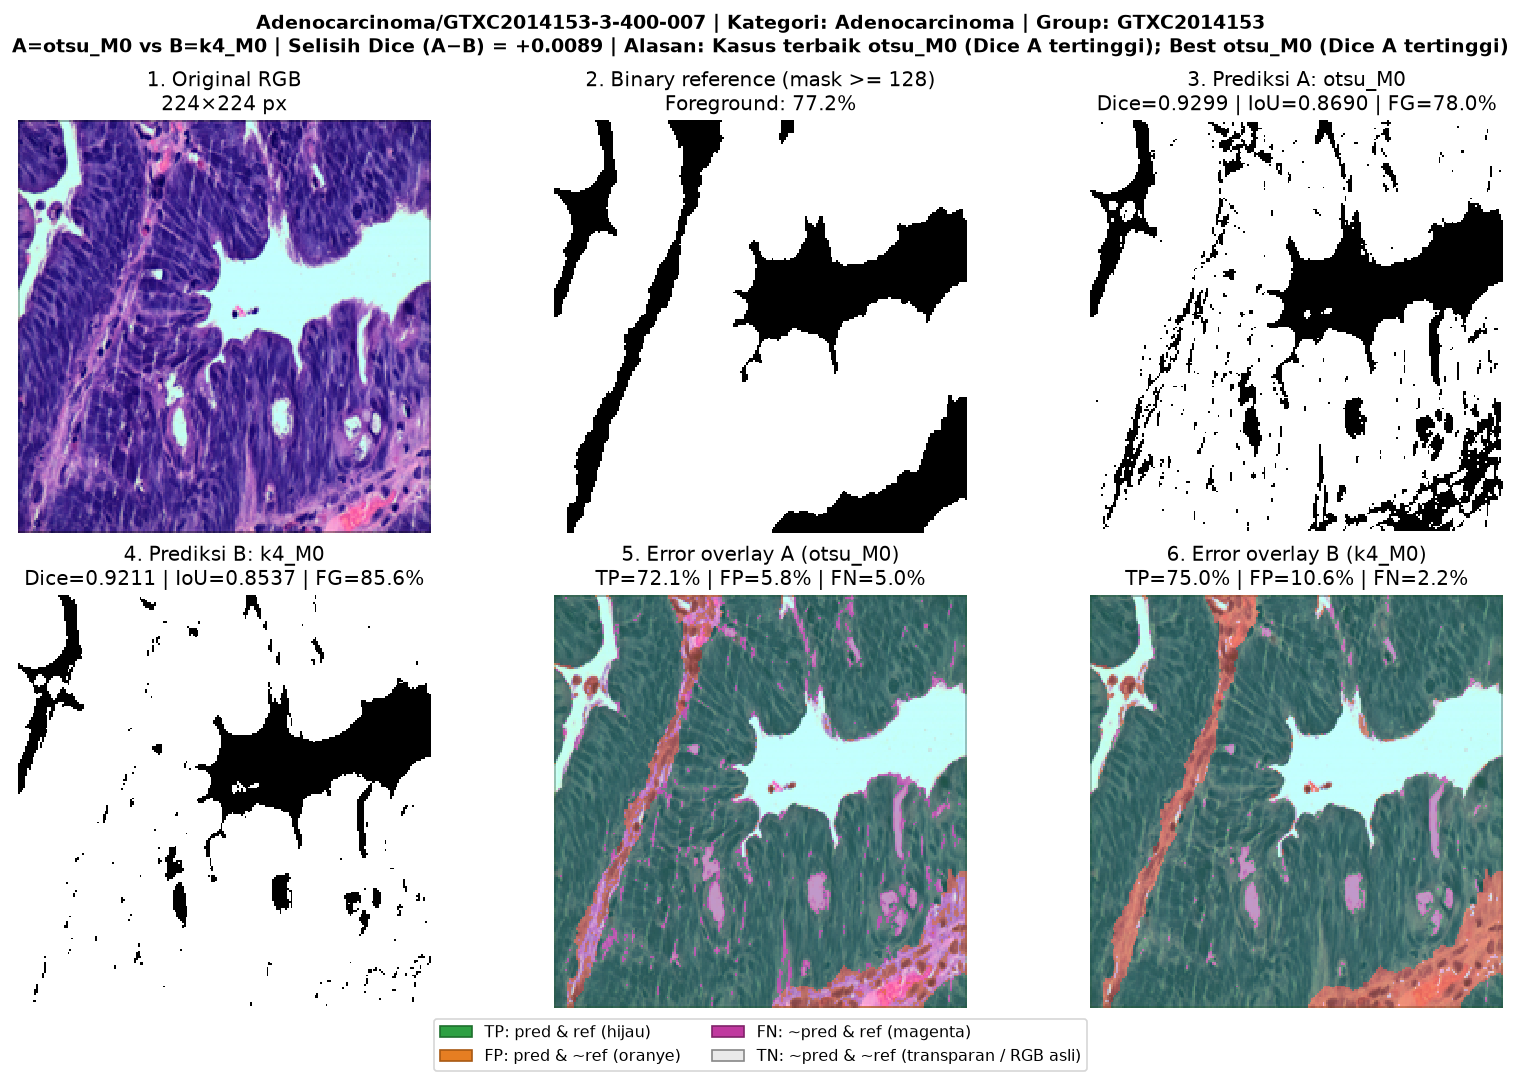

In [24]:
if 0 < len(extra_cases):
    case_e, _, exp_name = extra_cases[0]
    finish_figure(
        plot_segmentation_case(case_e),
        export_path=(ROOT / "reports/figures" / exp_name) if EXPORT_FIGURES else None,
    )

In [25]:
if 1 < len(extra_cases):
    case_e, note_label, _ = extra_cases[1]
    display(
        Markdown(
            f"#### {note_label}: `{case_e.sample_id}` (`{case_e.category}`, Group `{case_e.group_id}`)"
        )
    )
    display(format_case_metrics_for_display(case_metrics_table(case_e)))

#### Kasus terbaik k4_M0 (Dice B tertinggi): `Adenocarcinoma/GT2016882-1-400-001` (`Adenocarcinoma`, Group `GT2016882`)

,Metode,Dice,IoU,Precision,Recall,Pred FG (%),Ref FG (%),TP,FP,FN,TN
method,,,,,,,,,,,
otsu_M0,Otsu M0,0.9083,0.8320,0.9966,0.8344,70.32%,83.99%,35163,119,6980,7914
k4_M0,"K-means k=4, M0",0.9804,0.9615,0.9931,0.9680,81.87%,83.99%,40793,285,1350,7748


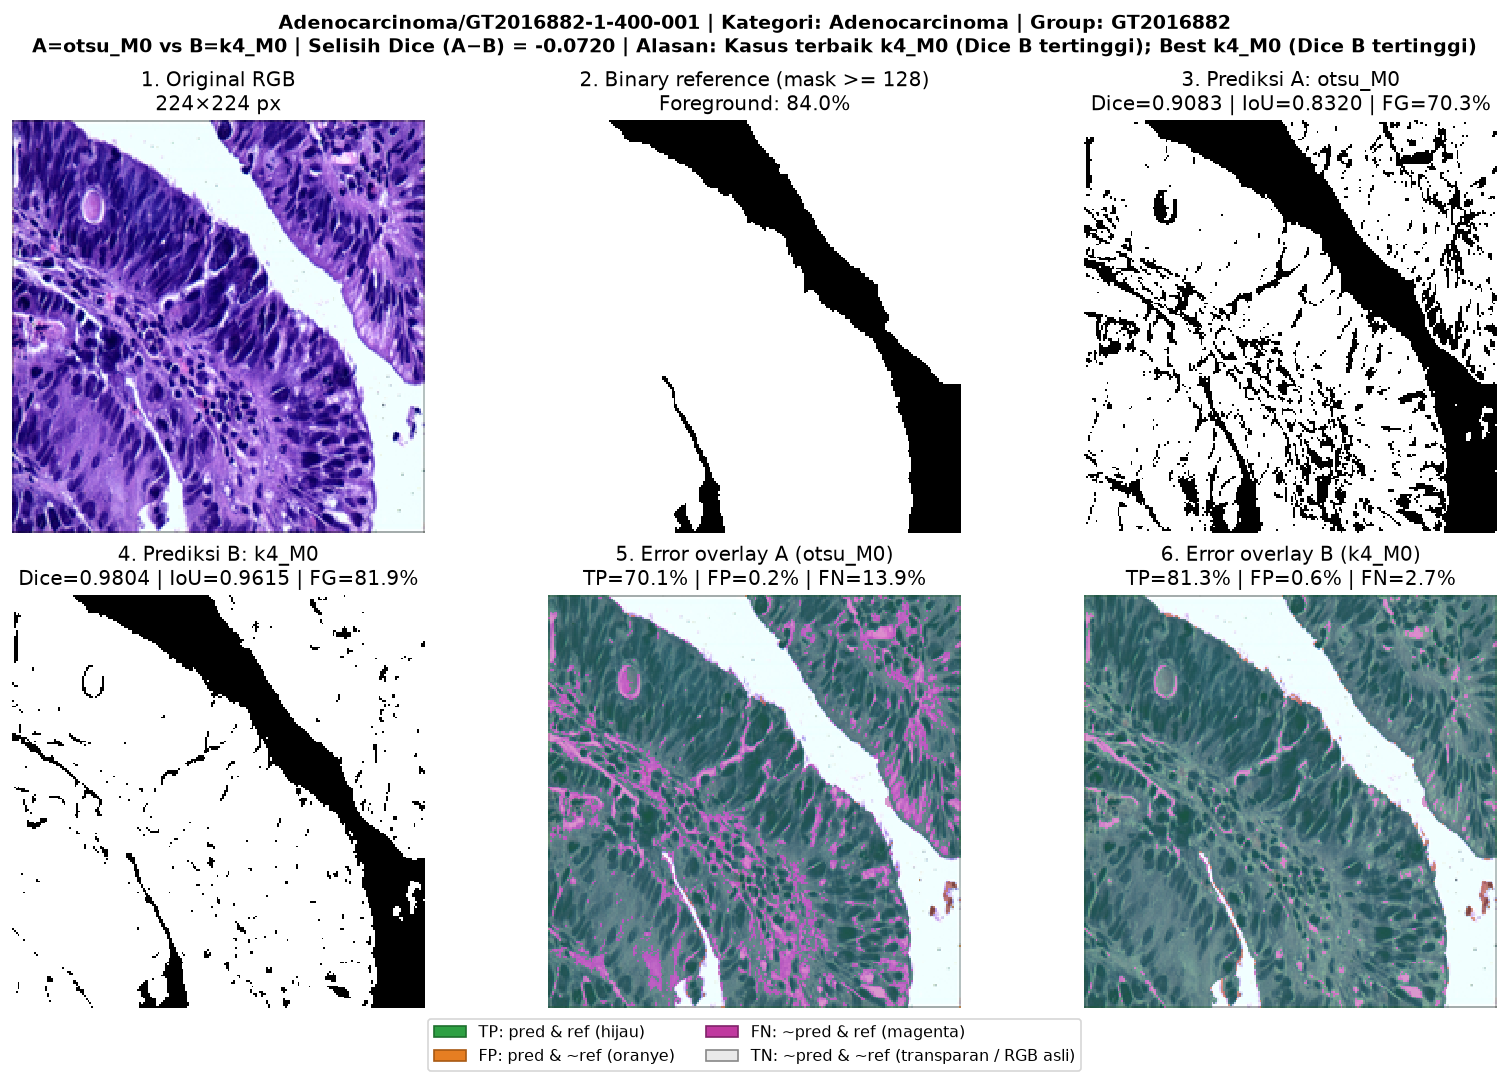

In [26]:
if 1 < len(extra_cases):
    case_e, _, exp_name = extra_cases[1]
    finish_figure(
        plot_segmentation_case(case_e),
        export_path=(ROOT / "reports/figures" / exp_name) if EXPORT_FIGURES else None,
    )

In [27]:
if 2 < len(extra_cases):
    case_e, note_label, _ = extra_cases[2]
    display(
        Markdown(
            f"#### {note_label}: `{case_e.sample_id}` (`{case_e.category}`, Group `{case_e.group_id}`)"
        )
    )
    display(format_case_metrics_for_display(case_metrics_table(case_e)))

#### Kedua metode lemah (both_poor non-duplikat): `Polyp/GT2014792-4-400-001` (`Polyp`, Group `GT2014792`)

,Metode,Dice,IoU,Precision,Recall,Pred FG (%),Ref FG (%),TP,FP,FN,TN
method,,,,,,,,,,,
otsu_M0,Otsu M0,0.4334,0.2766,0.5128,0.3752,45.87%,62.70%,11804,11213,19655,7504
k4_M0,"K-means k=4, M0",0.5426,0.3724,0.5097,0.5802,71.37%,62.70%,18252,17559,13207,1158


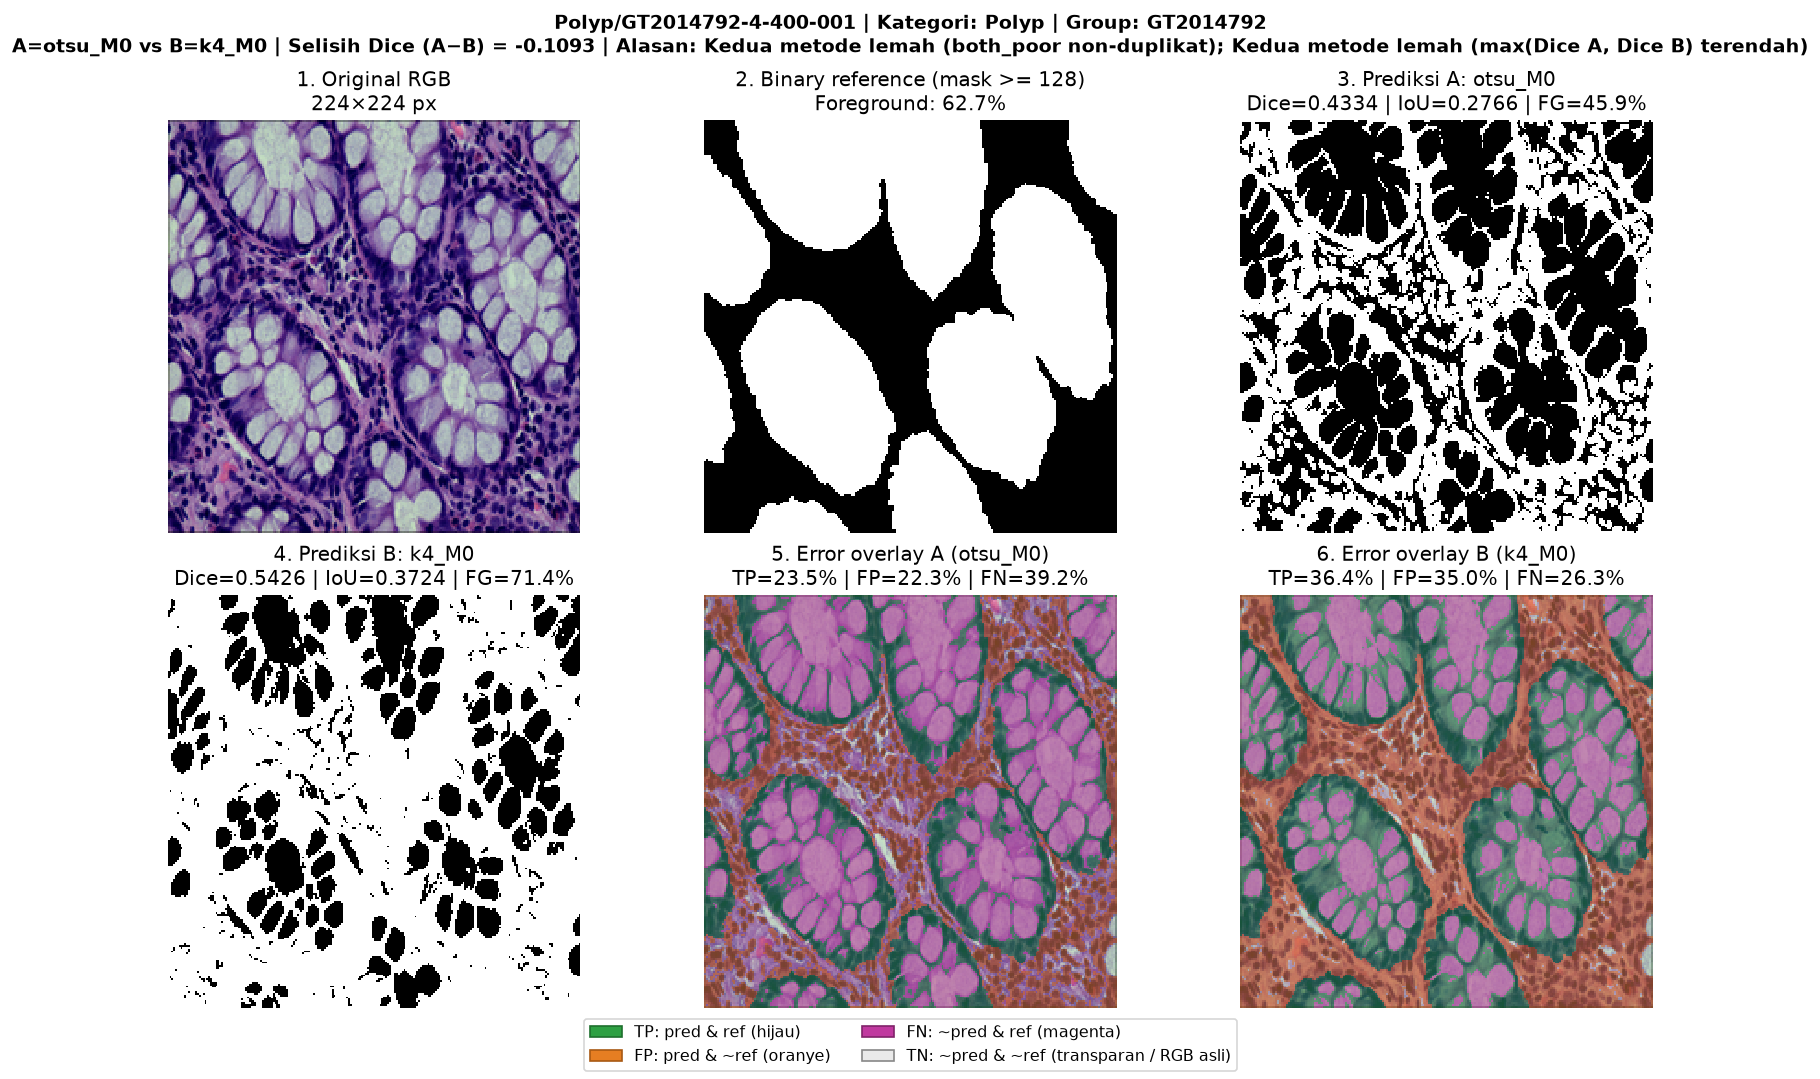

In [28]:
if 2 < len(extra_cases):
    case_e, _, exp_name = extra_cases[2]
    finish_figure(
        plot_segmentation_case(case_e),
        export_path=(ROOT / "reports/figures" / exp_name) if EXPORT_FIGURES else None,
    )

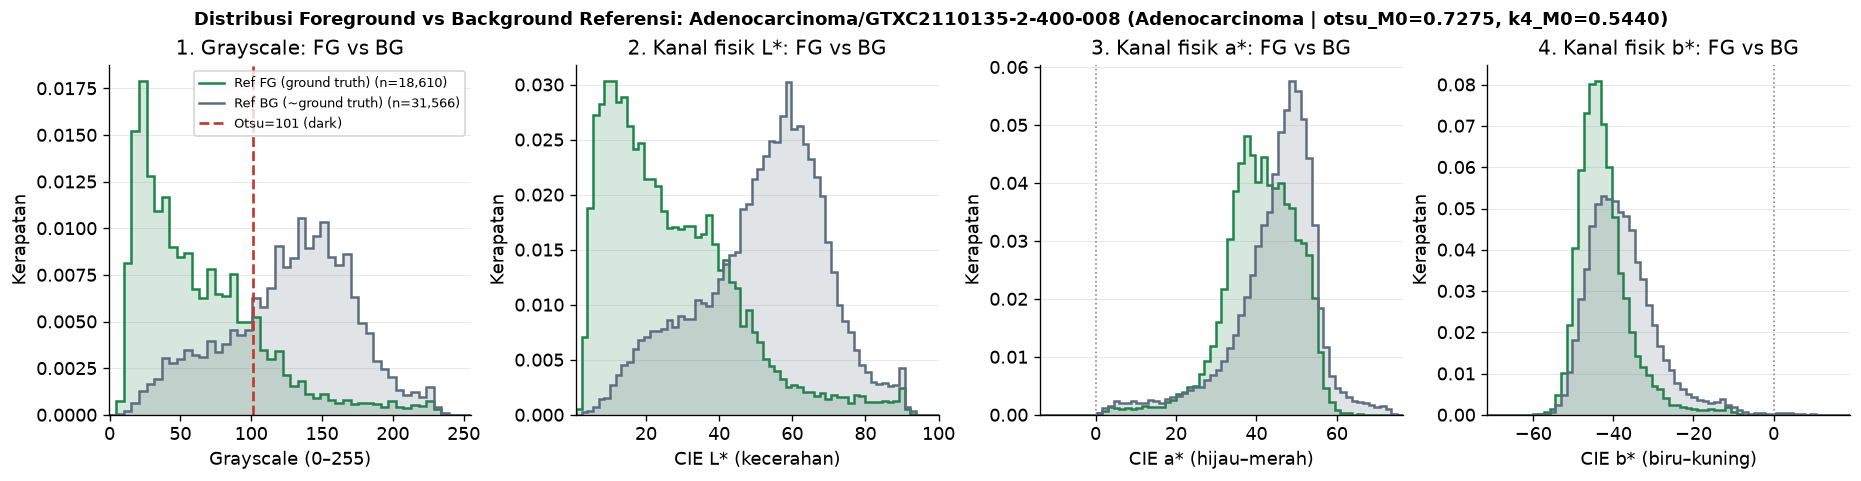

In [29]:
if RAW_AVAILABLE:
    sub_p = paired.loc[paired["sample_id"].eq('Adenocarcinoma/GTXC2110135-2-400-008')]
    if not sub_p.empty:
        case_fg = build_case(
            ROOT,
            row=sub_p.iloc[0],
            method_a=METHOD_A,
            method_b=METHOD_B,
            selection_reasons=('otsu_M0 unggul (FG lebih gelap daripada stroma BG)',),
            data_root_override=DATA_ROOT_OVERRIDE,
            split_df=split_df,
        )
        finish_figure(
            plot_fg_vs_bg_intensity_histograms(
                case_fg,
                bins=48,
                lab_edges=shared_lab_edges if "shared_lab_edges" in locals() else None,
                density=True,
            ),
            export_path=(ROOT / "reports/figures" / '05b_fg_vs_bg_otsu_advantage.png') if EXPORT_FIGURES else None,
        )

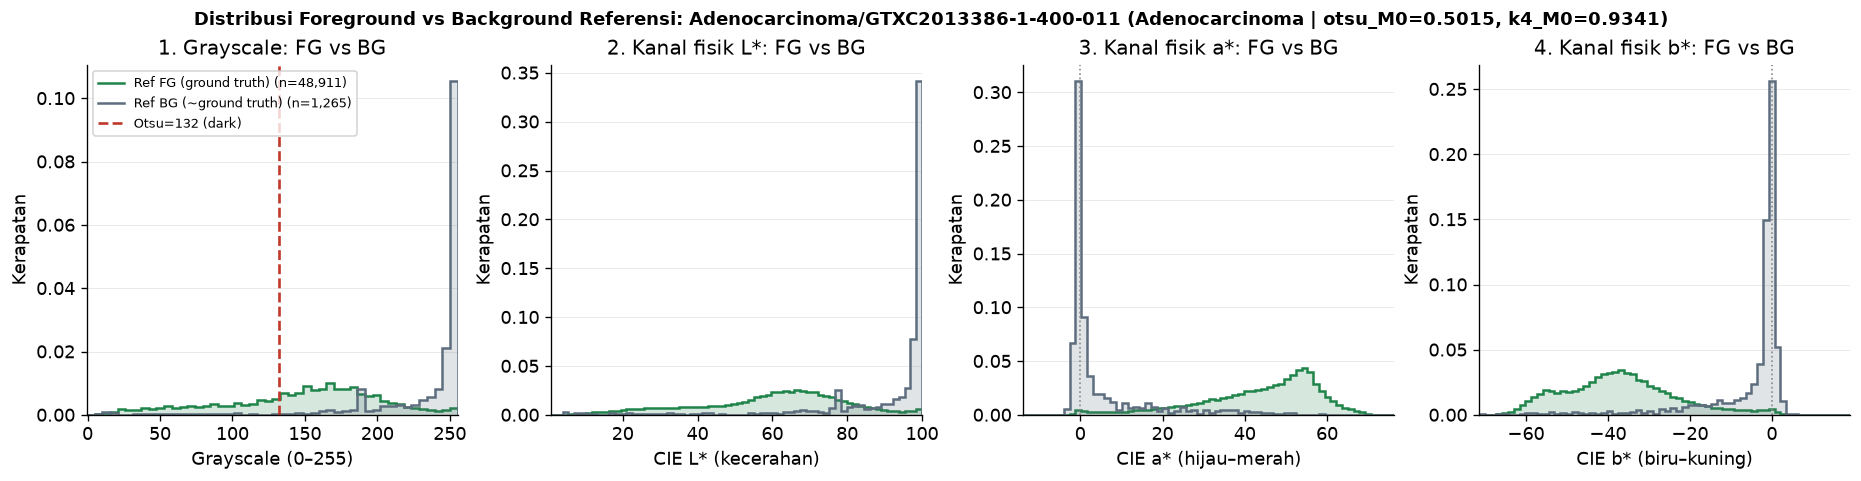

In [30]:
if RAW_AVAILABLE:
    sub_p = paired.loc[paired["sample_id"].eq('Adenocarcinoma/GTXC2013386-1-400-011')]
    if not sub_p.empty:
        case_fg = build_case(
            ROOT,
            row=sub_p.iloc[0],
            method_a=METHOD_A,
            method_b=METHOD_B,
            selection_reasons=('k4_M0 unggul (FG melampaui threshold gelap Otsu)',),
            data_root_override=DATA_ROOT_OVERRIDE,
            split_df=split_df,
        )
        finish_figure(
            plot_fg_vs_bg_intensity_histograms(
                case_fg,
                bins=48,
                lab_edges=shared_lab_edges if "shared_lab_edges" in locals() else None,
                density=True,
            ),
            export_path=(ROOT / "reports/figures" / '05b_fg_vs_bg_k4_advantage.png') if EXPORT_FIGURES else None,
        )

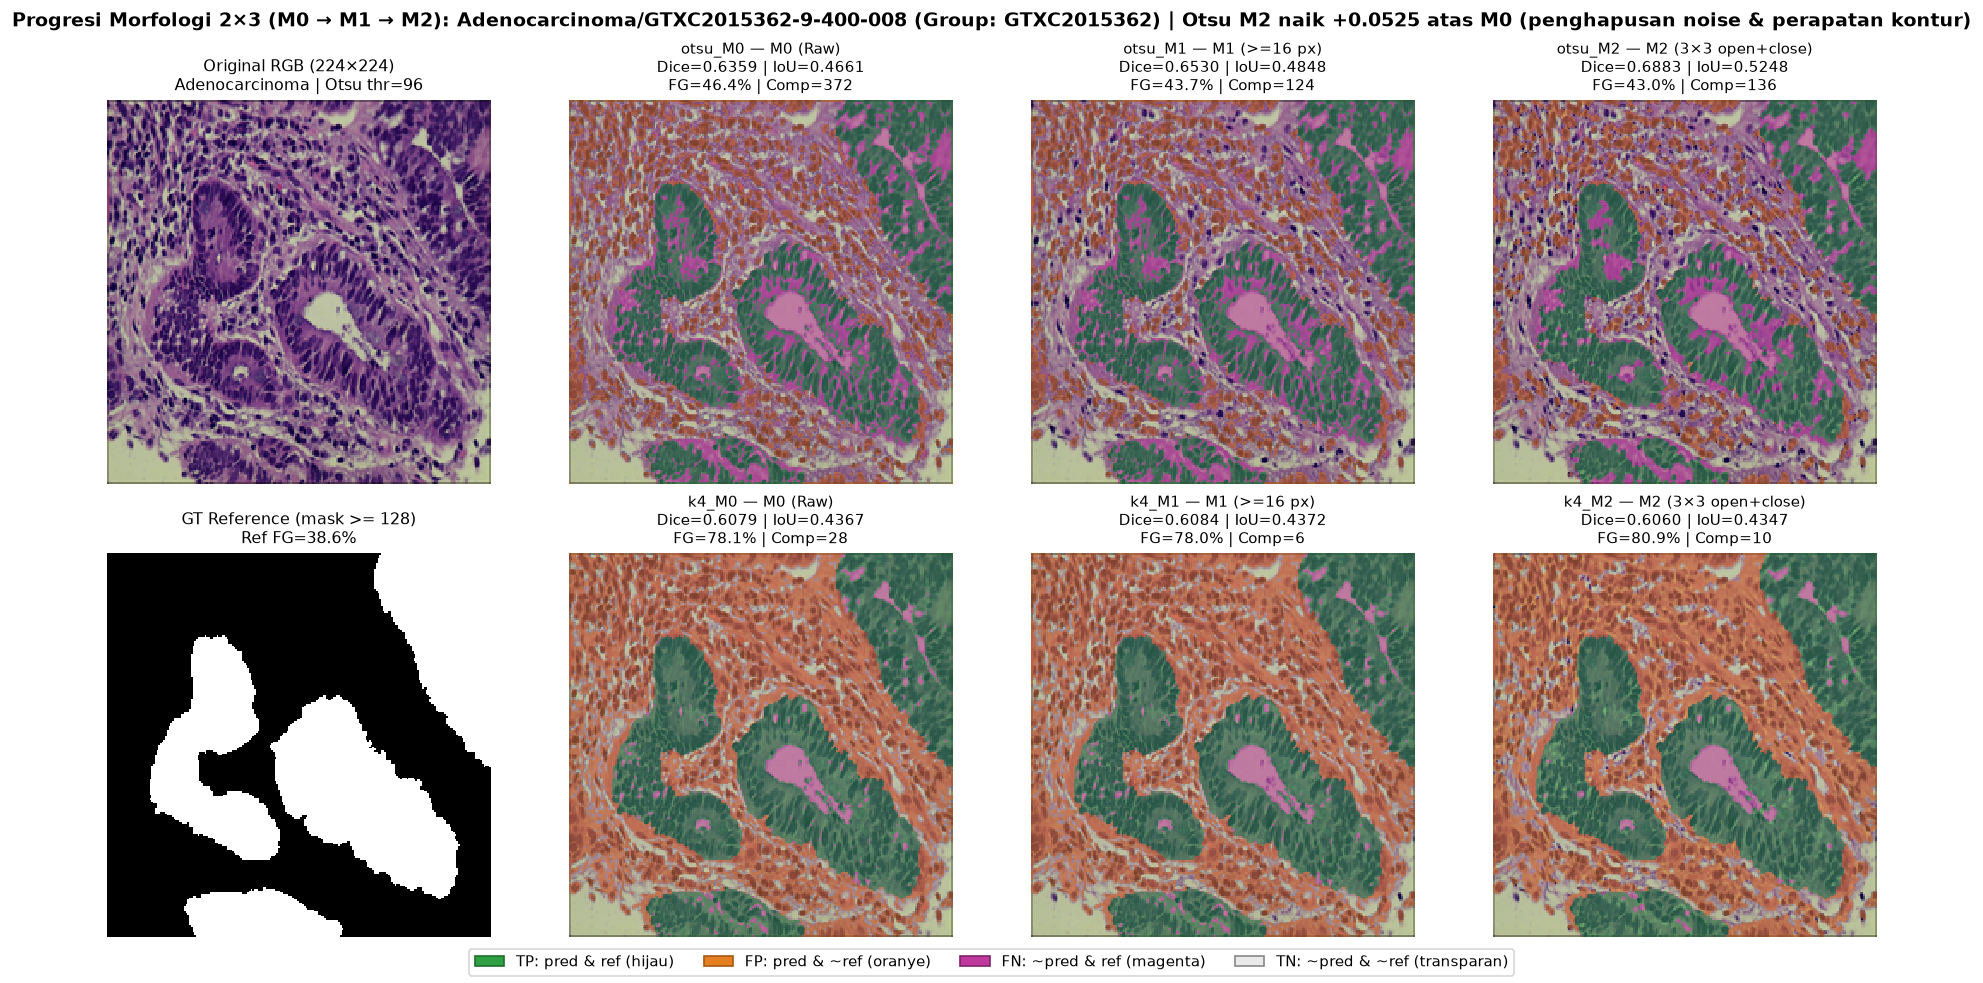

In [31]:
if RAW_AVAILABLE:
    finish_figure(
        plot_morphology_stage_comparison(
            ROOT,
            'Adenocarcinoma/GTXC2015362-9-400-008',
            reason_label='Otsu M2 naik +0.0525 atas M0 (penghapusan noise & perapatan kontur)',
            data_root_override=DATA_ROOT_OVERRIDE,
            split_df=split_df,
        ),
        export_path=(ROOT / "reports/figures" / '05b_morphology_M0_M1_M2_otsu_gain.png') if EXPORT_FIGURES else None,
    )

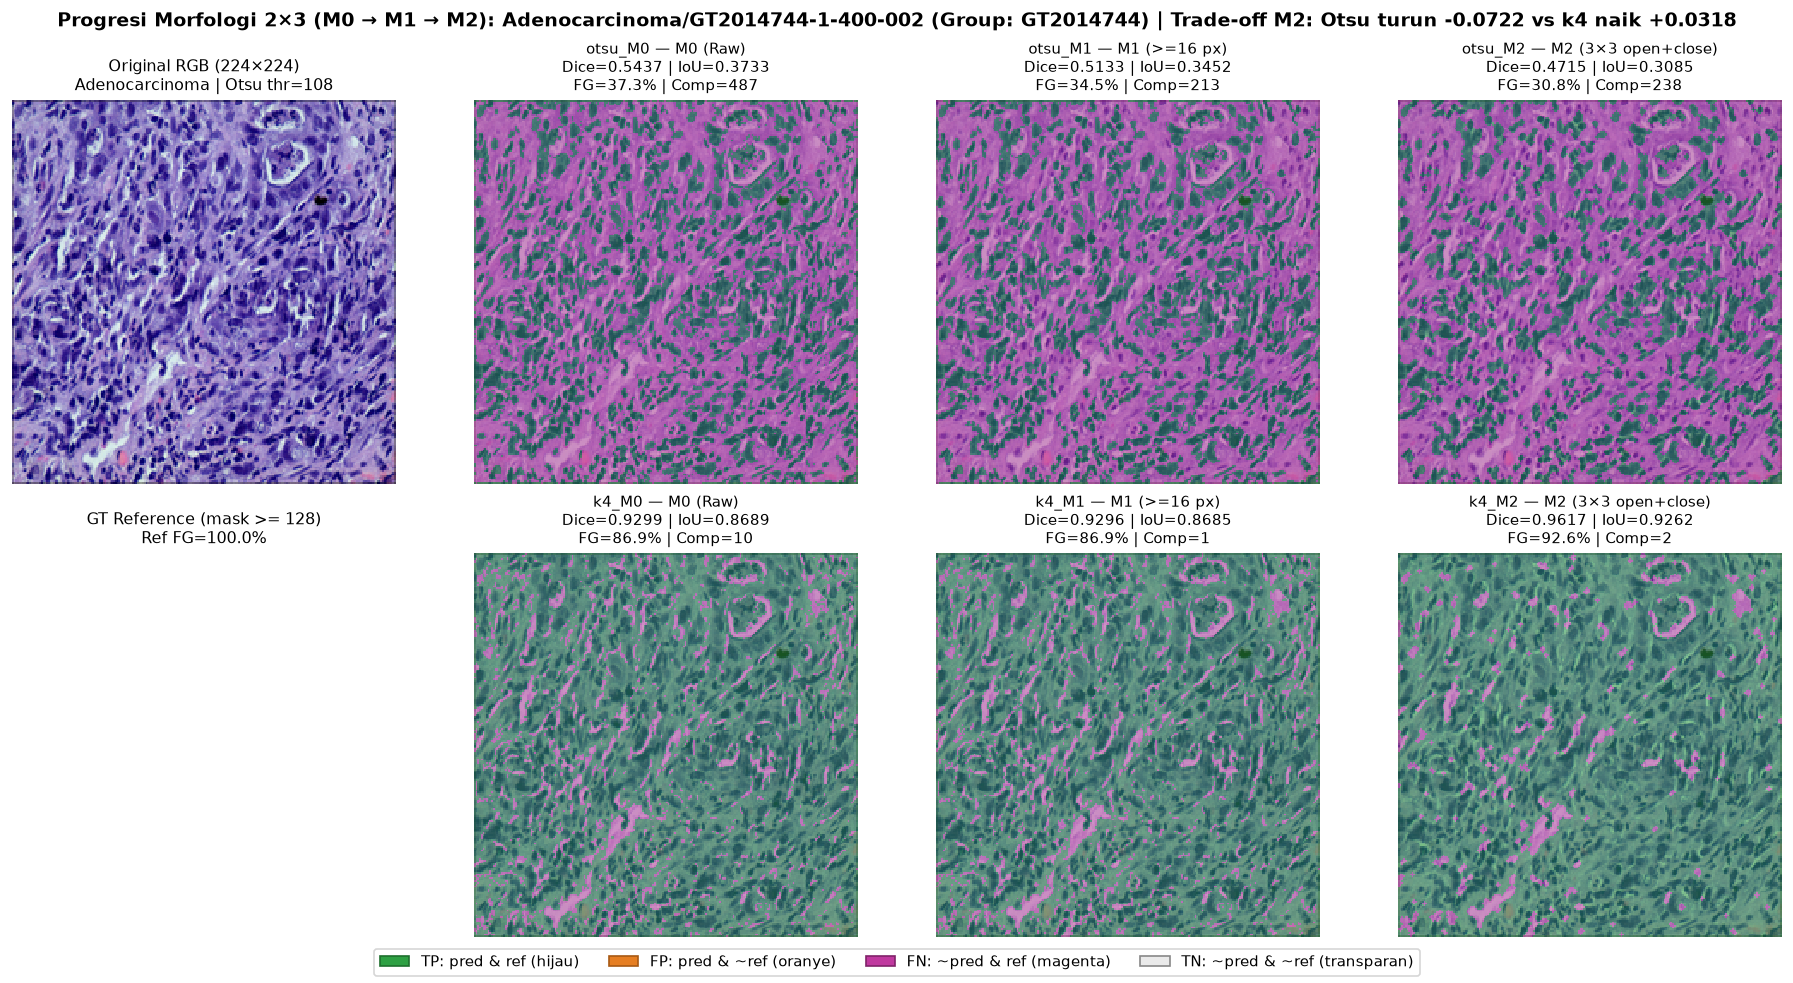

In [32]:
if RAW_AVAILABLE:
    finish_figure(
        plot_morphology_stage_comparison(
            ROOT,
            'Adenocarcinoma/GT2014744-1-400-002',
            reason_label='Trade-off M2: Otsu turun -0.0722 vs k4 naik +0.0318',
            data_root_override=DATA_ROOT_OVERRIDE,
            split_df=split_df,
        ),
        export_path=(ROOT / "reports/figures" / '05b_morphology_M0_M1_M2_tradeoff.png') if EXPORT_FIGURES else None,
    )

## 7. Eksplorasi interaktif tersinkronisasi (`ipywidgets`, opsional)

Jika dijalankan di VS Code atau Jupyter dengan dukungan *widget*, kontrol di bawah menyinkronkan pemilihan metode A/B, kategori, mode ranking, jumlah kasus, `sample_id`, dan mode histogram. Jika dibuka pada peninjau statis tanpa *widget renderer*, gunakan parameter pada sel awal notebook dan jalankan ulang sel.

In [33]:
def launch_case_explorer() -> None:
    try:
        import ipywidgets as widgets
    except ImportError:
        print("ipywidgets tidak terpasang; gunakan parameter sel atas untuk mengganti metode/kasus.")
        return

    method_opts = [(method_label(m), m) for m in SUPPORTED_METHODS]
    cat_opts = [("Semua 6 kategori", "All")] + [(c, c) for c in EXPECTED_CATEGORIES]
    mode_opts = [("Default 4 kasus unik", "default_four")] + [(m, m) for m in RANKING_MODES]

    w_ma = widgets.Dropdown(options=method_opts, value=METHOD_A, description="Metode A:")
    w_mb = widgets.Dropdown(options=method_opts, value=METHOD_B, description="Metode B:")
    w_cat = widgets.Dropdown(options=cat_opts, value=CATEGORY_FILTER or "All", description="Kategori:")
    w_mode = widgets.Dropdown(options=mode_opts, value=RANKING_MODE, description="Ranking:")
    w_n = widgets.BoundedIntText(value=2, min=1, max=6, step=1, description="Jml kasus:")
    w_sid = widgets.Dropdown(options=[("(Ikuti ranking)", "")], value="", description="Sample ID:")
    w_den = widgets.Checkbox(value=HISTOGRAM_DENSITY, description="Mode kerapatan (integral=1)")
    out = widgets.Output()

    def _refresh_sample_options(*_args) -> None:
        cat_val = None if w_cat.value == "All" else w_cat.value
        sub_p = pair_scores(results, w_ma.value, w_mb.value, category=cat_val)
        opts = [("(Ikuti ranking)", "")] + [(sid, sid) for sid in sub_p["sample_id"].tolist()]
        current = w_sid.value if any(w_sid.value == val for _, val in opts) else ""
        w_sid.options = opts
        w_sid.value = current

    def _render(*_args) -> None:
        with out:
            out.clear_output(wait=True)
            cat_val = None if w_cat.value == "All" else w_cat.value
            sub_p = pair_scores(results, w_ma.value, w_mb.value, category=cat_val)
            cnts, _ = paired_outcome_counts(sub_p)
            display(
                Markdown(
                    f"**Ringkasan filter aktif (`n={cnts['total']}`):** "
                    f"`{w_ma.value}` unggul `{cnts['a_higher']}` | "
                    f"`{w_mb.value}` unggul `{cnts['b_higher']}` | Tie `{cnts['tie']}`"
                )
            )
            fig_s = plot_score_histograms(sub_p, bins=20, category_label=cat_val or "Semua 6 kategori")
            finish_figure(fig_s, export_path=None)

            if w_sid.value:
                chosen_df = sub_p.loc[sub_p["sample_id"].eq(w_sid.value)].assign(
                    selection_reasons=f"Pilihan sample_id={w_sid.value}"
                )
            elif w_mode.value == "default_four":
                chosen_df = select_distinct_cases(sub_p)
            else:
                chosen_df = rank_cases(sub_p, mode=w_mode.value, n=int(w_n.value)).rename(
                    columns={"selection_reason": "selection_reasons"}
                )

            if chosen_df.empty:
                print("Tidak ada kasus yang memenuhi mode ranking ini.")
                return
            display(
                chosen_df[["sample_id", "category", "dice_a", "dice_b", "delta_dice", "selection_reasons"]]
                .style.format({"dice_a": "{:.4f}", "dice_b": "{:.4f}", "delta_dice": "{:+.4f}"})
            )
            if not RAW_AVAILABLE:
                print("Citra mentah tidak tersedia untuk merender galeri dan histogram piksel.")
                return
            cases_local = [
                build_case(
                    ROOT,
                    r,
                    w_ma.value,
                    w_mb.value,
                    selection_reasons=r["selection_reasons"],
                    data_root_override=DATA_ROOT_OVERRIDE,
                    split_df=split_df,
                )
                for _, r in chosen_df.iterrows()
            ]
            edges_local = compute_shared_lab_edges([rgb_to_lab(c.image_rgb) for c in cases_local], bins=HISTOGRAM_BINS)
            for c_item in cases_local:
                display(format_case_metrics_for_display(case_metrics_table(c_item)))
                finish_figure(plot_segmentation_case(c_item))
                finish_figure(
                    plot_image_histograms(c_item, bins=HISTOGRAM_BINS, lab_edges=edges_local, density=bool(w_den.value))
                )

    _refresh_sample_options()
    for ctrl in (w_ma, w_mb, w_cat):
        ctrl.observe(_refresh_sample_options, names="value")
    for ctrl in (w_ma, w_mb, w_cat, w_mode, w_n, w_sid, w_den):
        ctrl.observe(_render, names="value")

    ui = widgets.VBox(
        [
            widgets.HBox([w_ma, w_mb, w_cat]),
            widgets.HBox([w_mode, w_n, w_sid, w_den]),
            out,
        ]
    )
    display(ui)

if SHOW_INTERACTIVE_WIDGETS:
    launch_case_explorer()

In [34]:
input_hashes_after = {name: sha256_bytes(path) for name, path in protected_files.items()}
assert input_hashes_after == input_hashes_before, "Artefak eksperimen berubah saat analisis kasus dijalankan."
print(
    f"Selesai: analisis berpasangan 372 citra validasi, {len(built_cases)} kasus galeri terverifikasi paritas CSV, "
    "seluruh artefak historis tetap utuh."
)

Selesai: analisis berpasangan 372 citra validasi, 4 kasus galeri terverifikasi paritas CSV, seluruh artefak historis tetap utuh.
